<a href="https://colab.research.google.com/github/NatShed/SOTA_2026/blob/main/SOTA_16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №16: Визуальные токенизаторы и autoregressive image generation

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Обучить compact VQ-VAE.
- Измерить reconstruction и codebook utilization.
- Обучить autoregressive prior и сравнить sampling.

## Теоретическая часть

VQ-VAE кодирует изображение в grid latent vectors, заменяет каждый ближайшим codebook vector и декодирует. Индексы становятся visual tokens для autoregressive prior. Малый codebook ухудшает reconstruction, большой может иметь dead codes.

![VQ-VAE](https://raw.githubusercontent.com/CompVis/taming-transformers/master/assets/teaser.png)


VQ-VAE заменяет пространственные признаки ближайшими векторами кодбука, straight-through переносит градиент через дискретизацию. Conditional autoregressive prior предсказывает очередной visual token по уже известным индексам и метке класса.

Для индекса $k^*=\arg\min_k\|z_e-e_k\|_2^2$ straight-through задаёт $z_q=z_e+\operatorname{sg}(e_{k^*}-z_e)$. Perplexity кодов равна $\exp(-\sum_k p_k\log p_k)$.

### Экспериментальный протокол

MNIST train 20 000/test 2 000; 28×28→7×7 visual tokens. Два токенизатора K=16/64; обученный conditional Transformer; 1000 шагов каждого в полном режиме. Smoke 2 шага — только техническая проверка.

### Материалы

- [VQ-VAE](https://arxiv.org/abs/1711.00937)
- [Taming Transformers](https://github.com/CompVis/taming-transformers)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

Отрисовываем картинку кусками и учим предсказывать следующий кусов по предыдущему.

In [ ]:
# ============================================================
#  LAB 16 — VQ-VAE + autoregressive prior  |  Colab setup
# ============================================================
from pathlib import Path
import os, json, random, math, tempfile
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# --- inline backend (Colab default, но фиксируем явно) ---
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Image, Markdown

# --- config ---
SEED = 42
FAST_DEV_RUN = False
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BATCH = 128
STEPS = 2 if FAST_DEV_RUN else 1000
LATENT_DIM = 64
N_TOKENS = 49
H_LAT = W_LAT = 7
N_CLASSES = 10

# --- paths (Colab: /content) ---
ARTIFACTS = Path(os.environ.get("CV_ARTIFACTS", "artifacts")).resolve()
ARTIFACTS.mkdir(parents=True, exist_ok=True)
FIG_DIR = ARTIFACTS / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
DATA_ROOT = Path(os.environ.get("CV_COURSE_DATA", "data")).resolve()
DATA_ROOT.mkdir(parents=True, exist_ok=True)

def save_json(name, value):
    p = ARTIFACTS / name
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str))

# --- data (20k train / 2k test) ---
_tf = transforms.ToTensor()
_full_train = datasets.MNIST(str(DATA_ROOT), train=True,  download=True, transform=_tf)
_full_test  = datasets.MNIST(str(DATA_ROOT), train=False, download=True, transform=_tf)
train_ds = Subset(_full_train, range(20_000))
test_ds  = Subset(_full_test,  range(2_000))
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=2, drop_last=True)
test_loader  = DataLoader(test_ds,  batch_size=256,   shuffle=False, num_workers=2)

# --- pretty print helpers ---
plt.rcParams.update({"figure.dpi": 100, "savefig.bbox": "tight",
                     "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})

def stage_header(num, title, subtitle=""):
    display(HTML(f"""
    <div style="background:linear-gradient(135deg,#0f172a,#1e40af);color:white;
                padding:16px 20px;border-radius:10px;margin:18px 0 10px 0;
                font-family:-apple-system,sans-serif;box-shadow:0 4px 12px rgba(0,0,0,.15)">
      <div style="font-size:11px;opacity:.75;letter-spacing:2px;text-transform:uppercase;">Этап {num}</div>
      <div style="font-size:22px;font-weight:800;margin-top:2px;">{title}</div>
      <div style="font-size:13px;opacity:.9;margin-top:6px;">{subtitle}</div>
    </div>"""))

def metrics_table(title, rows, accent="#1e40af"):
    h = ('<table style="border-collapse:separate;border-spacing:0;font-family:sans-serif;'
         'font-size:13px;margin:6px 0;box-shadow:0 2px 8px rgba(0,0,0,.08);'
         'border-radius:8px;overflow:hidden">')
    h += (f'<tr><th colspan="2" style="background:{accent};color:white;padding:8px 12px;'
          f'text-align:left">{title}</th></tr>')
    for i, (k, v) in enumerate(rows):
        bg = "#ffffff" if i % 2 == 0 else "#f8fafc"
        h += (f'<tr style="background:{bg}">'
              f'<td style="padding:6px 12px;border-bottom:1px solid #e2e8f0;color:#475569">{k}</td>'
              f'<td style="padding:6px 12px;border-bottom:1px solid #e2e8f0;font-weight:700;'
              f'color:#0f172a;font-family:monospace">{v}</td></tr>')
    display(HTML(h + '</table>'))

def note(text):
    display(HTML(f'<div style="background:#fffbeb;border-left:4px solid #f59e0b;'
                 f'padding:10px 14px;margin:10px 0;font-family:sans-serif;'
                 f'font-size:13px;border-radius:0 8px 8px 0">{text}</div>'))

def success(text):
    display(HTML(f'<div style="background:#ecfdf5;border-left:4px solid #10b981;'
                 f'padding:10px 14px;margin:10px 0;font-family:sans-serif;'
                 f'font-size:13px;border-radius:0 8px 8px 0">✓ {text}</div>'))

def _savefig(fig, name, show=True):
    """Сохранить на диск → закрыть → показать через Image(filename=...) — надёжно в Colab."""
    p = FIG_DIR / name
    fig.savefig(p, dpi=130, bbox_inches="tight")
    plt.close(fig)
    if show:
        display(Image(filename=str(p)))
    return p

def show_image_grid(imgs, titles=None, ncols=8, title="", cmap="gray", name=None):
    if isinstance(imgs, torch.Tensor): imgs = imgs.detach().cpu()
    if imgs.ndim == 4: imgs = imgs.squeeze(1)
    N = imgs.size(0); nrows = math.ceil(N / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.4, nrows * 1.7))
    axes = np.array(axes).reshape(-1)
    for i, ax in enumerate(axes):
        ax.axis("off")
        if i < N:
            ax.imshow(imgs[i].numpy(), cmap=cmap, vmin=0, vmax=1)
            if titles is not None and i < len(titles):
                ax.set_title(str(titles[i]), fontsize=8)
    if title: fig.suptitle(title, y=1.02)
    if name: _savefig(fig, name)
    else: plt.show(); plt.close(fig)

def plot_lines(series, title, xlabel, ylabel, name, logy=False):
    fig, ax = plt.subplots(figsize=(9, 4))
    for label, pts in series.items():
        xs = [p[0] for p in pts]; ys = [p[1] for p in pts]
        ax.plot(xs, ys, marker="o", markersize=3, label=label)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    if logy: ax.set_yscale("log")
    ax.legend()
    return _savefig(fig, name)

print(f"✓ setup | device={DEVICE} | fast={FAST_DEV_RUN} | steps={STEPS}")
print(f"  data={DATA_ROOT}")
print(f"  artifacts={ARTIFACTS}")
print(f"  figures={FIG_DIR}")

✓ setup | device=cuda | fast=False | steps=1000
  data=/content/data
  artifacts=/content/artifacts
  figures=/content/artifacts/figures


### Архитектура дискретного токенизатора

*Вес: 1 балл.*

**Постановка.** Кодбук должен обучаться на реальных изображениях; random inputs не измеряют качество реконструкции. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите VQ-VAE, ближайший код, straight-through и loss с корректными масштабами.

**Результат.** Проверяемое состояние «Архитектура дискретного токенизатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите VQ-VAE, ближайший код, straight-through и loss с корректными масштабами» и его результат доступен следующему этапу.

Encoder — берёт картинку 28×28 и превращает в «сетку признаков» 7×7.

Vector Quantizer (кодбук) — самое интересное: для каждого из 49 векторов-признаков находит ближайший код из заранее заданного словаря (кодбука). У словаря K вариантов: 16 или 64. Как будто каждой точке картинки присваиваем «номер ближайшего слова в словаре».

Decoder — по этим 49 номерам пытается восстановить исходную картинку.

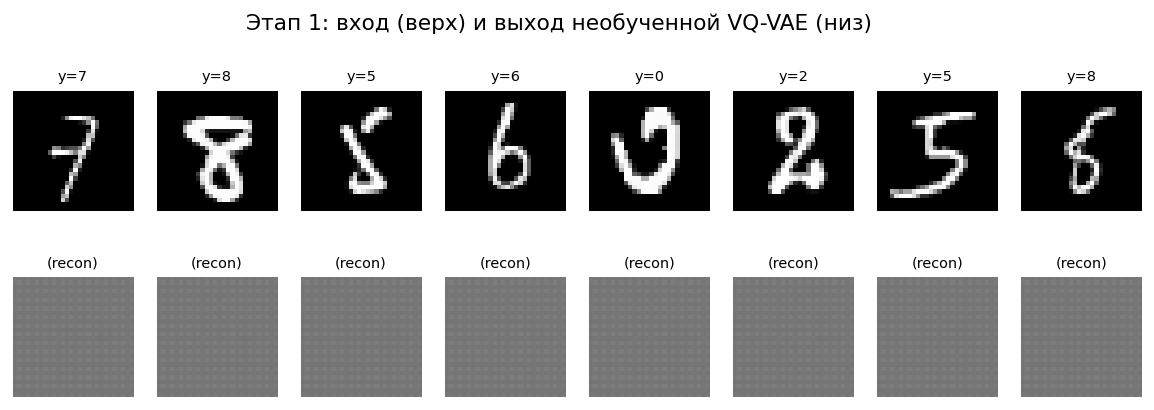

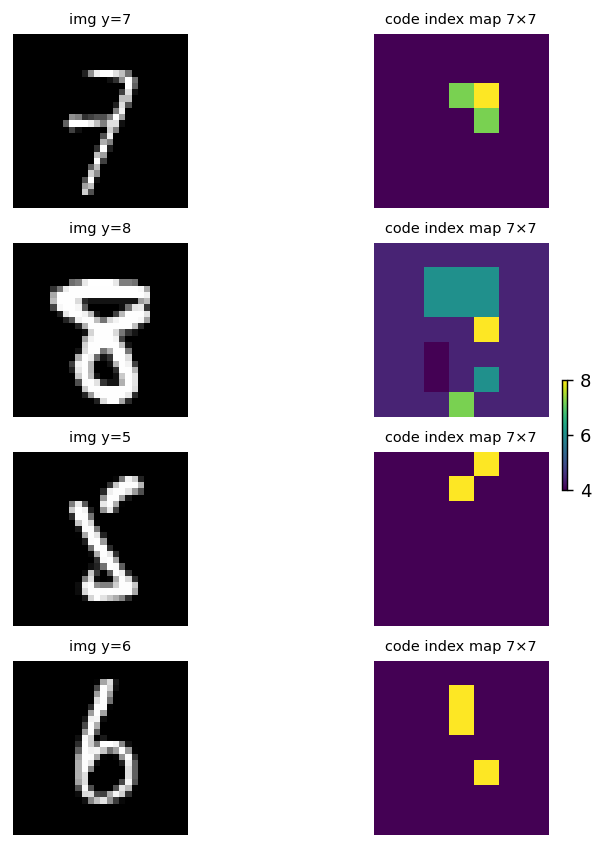

In [ ]:
stage_header(1, "Архитектура дискретного токенизатора",
             "VQ-VAE: encoder → nearest code (straight-through) → decoder")

class VectorQuantizer(nn.Module):
    def __init__(self, K, D, beta=0.25):
        super().__init__()
        self.K, self.D, self.beta = K, D, beta
        self.embedding = nn.Embedding(K, D)
        self.embedding.weight.data.uniform_(-1.0 / K, 1.0 / K)
    def forward(self, z):
        B, D, H, W = z.shape
        z_ch = z.permute(0, 2, 3, 1).contiguous()
        flat = z_ch.view(-1, D)
        d = (flat.pow(2).sum(1, keepdim=True)
             - 2 * flat @ self.embedding.weight.t()
             + self.embedding.weight.pow(2).sum(1, keepdim=True).t())
        idx = d.argmin(1)
        zq_ch = self.embedding(idx).view(B, H, W, D)
        vq_loss = (F.mse_loss(zq_ch, z_ch.detach())
                   + self.beta * F.mse_loss(z_ch, zq_ch.detach()))
        zq = (z_ch + (zq_ch - z_ch).detach()).permute(0, 3, 1, 2).contiguous()
        probs = F.one_hot(idx, self.K).float().mean(0)
        perp = torch.exp(-(probs * (probs + 1e-10).log()).sum())
        return zq, vq_loss, idx.view(B, H, W), perp

class Encoder(nn.Module):
    def __init__(self, D=LATENT_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(64, D, 3, 1, 1))
    def forward(self, x): return self.net(x)

class Decoder(nn.Module):
    def __init__(self, D=LATENT_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(D, 64, 3, 1, 1), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 4, 2, 1), nn.Sigmoid())
    def forward(self, x): return self.net(x)

class VQVAE(nn.Module):
    def __init__(self, K, D=LATENT_DIM):
        super().__init__()
        self.K, self.D = K, D
        self.enc = Encoder(D); self.vq = VectorQuantizer(K, D); self.dec = Decoder(D)
    def forward(self, x):
        z = self.enc(x); zq, vl, idx, perp = self.vq(z)
        return self.dec(zq), vl, idx, perp

x_smoke, y_smoke = next(iter(train_loader))
x_smoke = x_smoke.to(DEVICE)
m = VQVAE(K=16).to(DEVICE)
with torch.no_grad():
    xr, vl, idx, perp = m(x_smoke)

metrics_table("VQ-VAE architecture", [
    ("Параметров (K=16)",     f"{sum(p.numel() for p in m.parameters()):,}"),
    ("Вход",                  f"({BATCH}, 1, 28, 28)"),
    ("Латент после encoder",  f"({BATCH}, {LATENT_DIM}, 7, 7)"),
    ("Visual tokens",         f"({BATCH}, 7, 7) = {N_TOKENS} на картинку"),
    ("Реконструкция",         f"({BATCH}, 1, 28, 28)"),
    ("Straight-through",      "zq = z + (zq - z).detach()"),
    ("vq_loss",               "codebook_mse + 0.25 · commitment_mse"),
    ("Smoke vq_loss",         f"{float(vl):.4f}"),
    ("Smoke perplexity",      f"{float(perp):.2f}"),
])

show_image_grid(
    torch.cat([x_smoke[:8].cpu(), xr[:8].cpu()], 0),
    titles=[f"y={int(y)}" for y in y_smoke[:8]] + ["(recon)"] * 8,
    ncols=8, title="Этап 1: вход (верх) и выход необученной VQ-VAE (низ)",
    name="s1_smoke_recon.png")

fig, axes = plt.subplots(4, 2, figsize=(6, 8))
for i in range(4):
    axes[i, 0].imshow(x_smoke[i, 0].cpu(), cmap="gray"); axes[i, 0].axis("off")
    axes[i, 0].set_title(f"img y={int(y_smoke[i])}", fontsize=8)
    im = axes[i, 1].imshow(idx[i].cpu().numpy(), cmap="viridis")
    axes[i, 1].axis("off"); axes[i, 1].set_title("code index map 7×7", fontsize=8)
fig.colorbar(im, ax=axes[:, -1], fraction=0.02)
_savefig(fig, "s1_smoke_codemap.png")

save_json("s1_arch_check.json", {
    "params": sum(p.numel() for p in m.parameters()),
    "xr_shape": list(xr.shape), "idx_shape": list(idx.shape),
    "vq_loss": float(vl), "perp": float(perp)})
success(f"VQ-VAE собран. vq_loss={float(vl):.4f}, perplexity={float(perp):.2f}")

### Обучение и диагностика двух кодбуков

*Вес: 1 балл.*

**Постановка.** Кодбук должен обучаться на реальных изображениях; random inputs не измеряют качество реконструкции. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите K=16/64 при равном бюджете; измерьте test MSE, used/dead/perplexity и сохраните checkpoint.

**Результат.** Проверяемое состояние «Обучение и диагностика двух кодбуков» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите K=16/64 при равном бюджете; измерьте test MSE, used/dead/perplexity и сохраните checkpoint» и его результат доступен следующему этапу.

Маленький словарь (16) — все коды используются, но точность восстановления хуже: 16 «слов» не хватает, чтобы описать всё разнообразие цифр.

Большой словарь (64) — восстанавливает точнее, но появляется риск мёртвых кодов: часть слов никто не использует

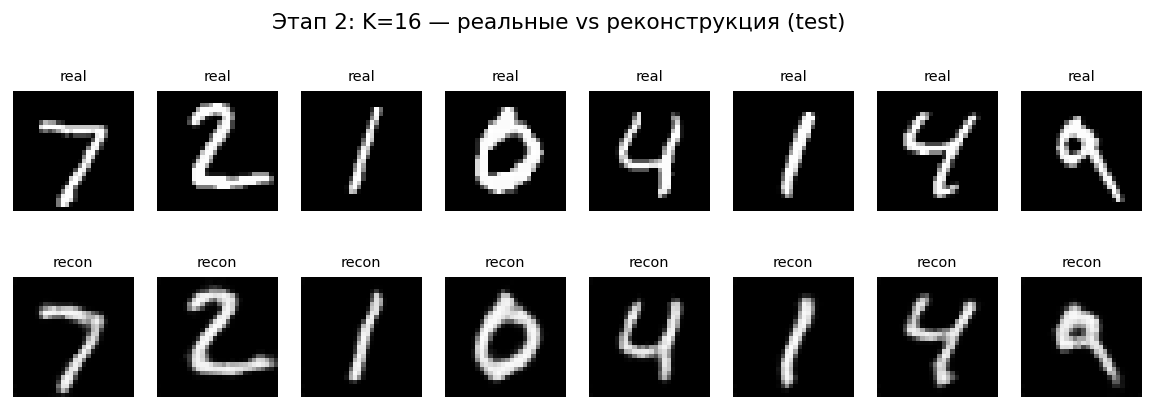

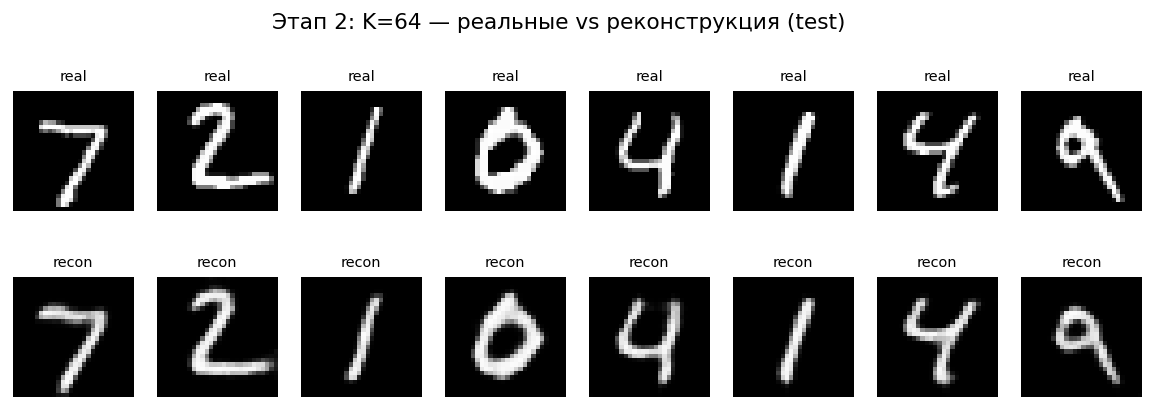

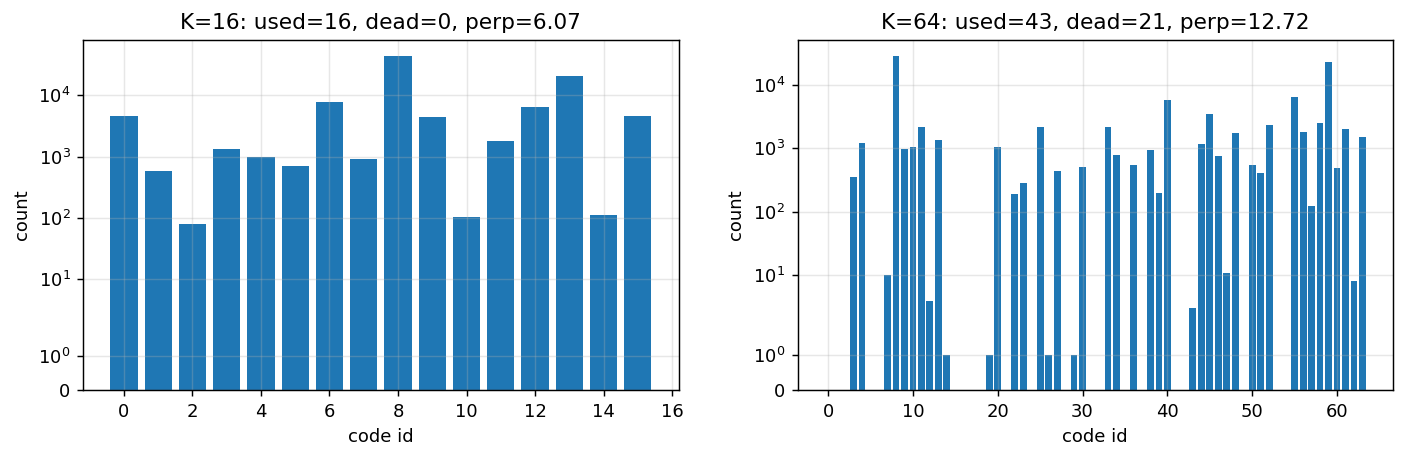

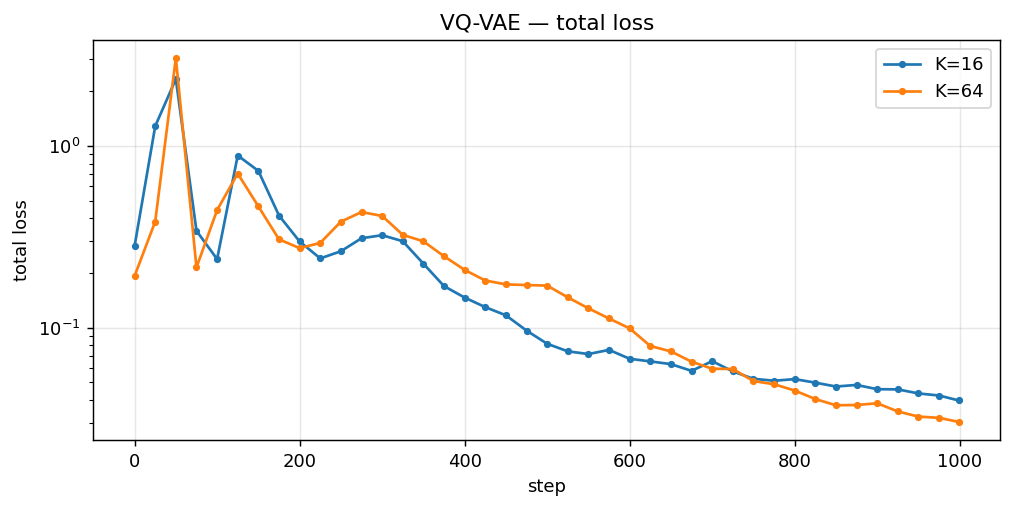

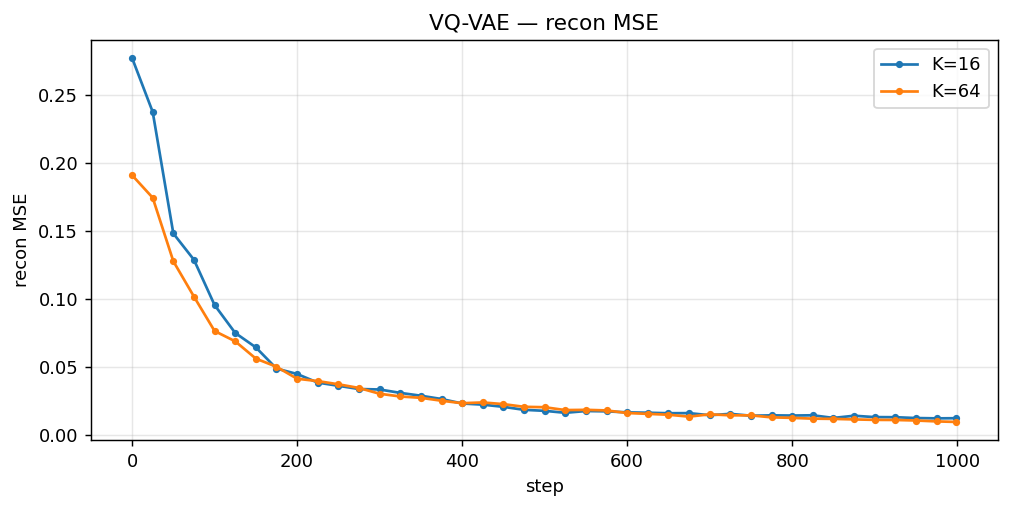

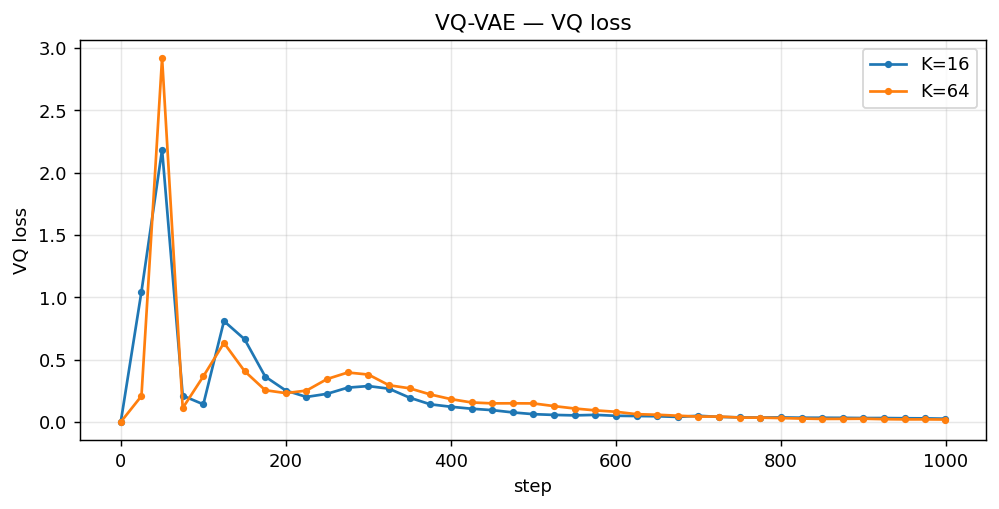

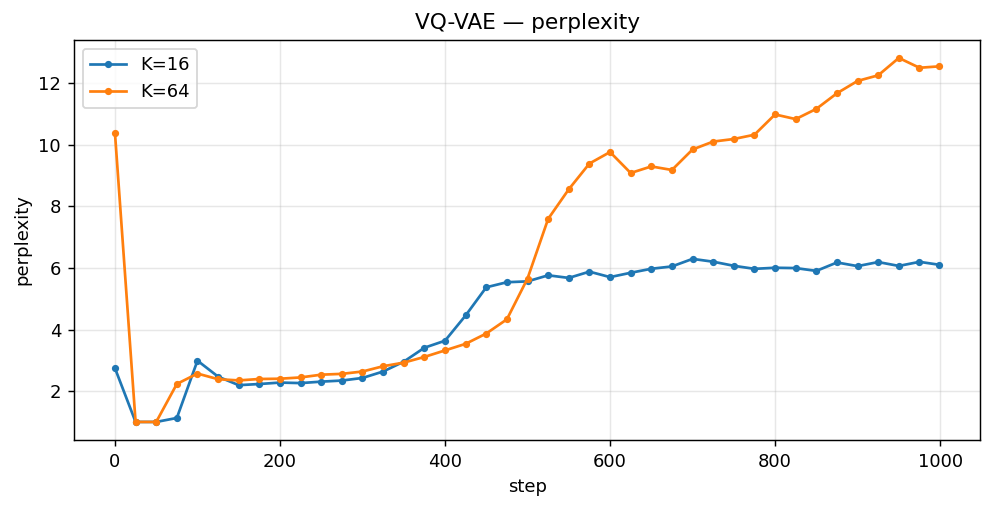

In [ ]:
stage_header(2, "Обучение и диагностика двух кодбуков",
             "K=16 vs K=64, равный бюджет: test MSE, used/dead, perplexity")

def train_vqvae(K, steps):
    model = VQVAE(K=K).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=3e-4)
    it = iter(train_loader); hist = []
    model.train()
    for step in range(steps):
        try: x, _ = next(it)
        except StopIteration: it = iter(train_loader); x, _ = next(it)
        x = x.to(DEVICE)
        xr, vq_loss, _, perp = model(x)
        recon = F.mse_loss(xr, x); loss = recon + vq_loss
        opt.zero_grad(); loss.backward(); opt.step()
        if step % max(1, steps // 40) == 0 or step == steps - 1:
            hist.append(dict(step=step, loss=loss.item(), recon=recon.item(),
                             vq=vq_loss.item(), perp=perp.item()))
    torch.save({"state": model.state_dict(), "K": K, "D": LATENT_DIM},
               ARTIFACTS / f"vqvae_K{K}.pt")
    return model, hist

@torch.no_grad()
def eval_vqvae(model):
    model.eval()
    se, n = 0.0, 0
    counts = torch.zeros(model.K, dtype=torch.long)
    demo_in, demo_out = [], []
    for bi, (x, _) in enumerate(test_loader):
        x = x.to(DEVICE)
        xr, _, idx, _ = model(x)
        se += ((xr - x) ** 2).sum().item(); n += x.numel()
        counts += torch.bincount(idx.cpu().flatten(), minlength=model.K)
        if bi == 0: demo_in, demo_out = x[:8].cpu(), xr[:8].cpu()
    mse = se / n
    used = int((counts > 0).sum()); dead = model.K - used
    p = counts.float() / counts.sum().clamp(min=1)
    perp = float(torch.exp(-(p * (p + 1e-10).log()).sum()))
    return dict(test_mse=mse, used=used, dead=dead, perplexity=perp,
                counts=counts, demo_in=demo_in, demo_out=demo_out)

vqvae_models, vqvae_metrics = {}, {}
for K in (16, 64):
    m, h = train_vqvae(K, STEPS)
    met = eval_vqvae(m); met["hist"] = h
    vqvae_models[f"K{K}"] = m; vqvae_metrics[f"K{K}"] = met
    metrics_table(f"VQ-VAE K={K} — test", [
        ("Test MSE",   f"{met['test_mse']:.5f}"),
        ("Used codes", f"{met['used']} / {K}"),
        ("Dead codes", f"{met['dead']}"),
        ("Perplexity", f"{met['perplexity']:.3f}"),
    ], accent="#16a34a")

for K in (16, 64):
    met = vqvae_metrics[f"K{K}"]
    show_image_grid(
        torch.cat([met["demo_in"], met["demo_out"]], 0),
        titles=["real"] * 8 + ["recon"] * 8, ncols=8,
        title=f"Этап 2: K={K} — реальные vs реконструкция (test)",
        name=f"s2_recon_K{K}.png")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for ax, K in zip(axes, (16, 64)):
    met = vqvae_metrics[f"K{K}"]; cc = met["counts"].numpy()
    ax.bar(np.arange(K), cc, color=np.where(cc > 0, "tab:blue", "tab:red"))
    ax.set_yscale("symlog")
    ax.set_title(f"K={K}: used={met['used']}, dead={met['dead']}, perp={met['perplexity']:.2f}")
    ax.set_xlabel("code id"); ax.set_ylabel("count")
_savefig(fig, "s2_code_usage.png")

for key, ylabel, fname in [("loss","total loss","s2_curve_loss.png"),
                            ("recon","recon MSE","s2_curve_recon.png"),
                            ("vq","VQ loss","s2_curve_vq.png"),
                            ("perp","perplexity","s2_curve_perp.png")]:
    series = {f"K={K}": [(r["step"], r[key]) for r in vqvae_metrics[f"K{K}"]["hist"]]
              for K in (16, 64)}
    plot_lines(series, f"VQ-VAE — {ylabel}", "step", ylabel, fname,
               logy=(key == "loss"))

save_json("s2_vqvae_metrics.json",
    {k: {kk: vv for kk, vv in v.items() if kk not in ("hist","counts","demo_in","demo_out")}
     for k, v in vqvae_metrics.items()})
success("Оба кодбука обучены; checkpoints в artifacts/vqvae_K*.pt")

Test MSE — ошибка восстановления (чем меньше, тем лучше).

Used / dead — сколько кодов реально используется.

Perplexity — насколько равномерно используется словарь.

 K=64 дал MSE 0.0101 против 0.0122 у K=16 (на 18% лучше), но из 64 кодов работает только 43. То есть больший словарь точнее, но недогружен.

### Индексы обученного токенизатора

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Закодируйте train/test только обученной VQ-VAE K=64.

**Результат.** Проверяемое состояние «Индексы обученного токенизатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Закодируйте train/test только обученной VQ-VAE K=64» и его результат доступен следующему этапу.

Переводим весть мнист в токены, каждая картинка становится последовательностью из 49 чисел

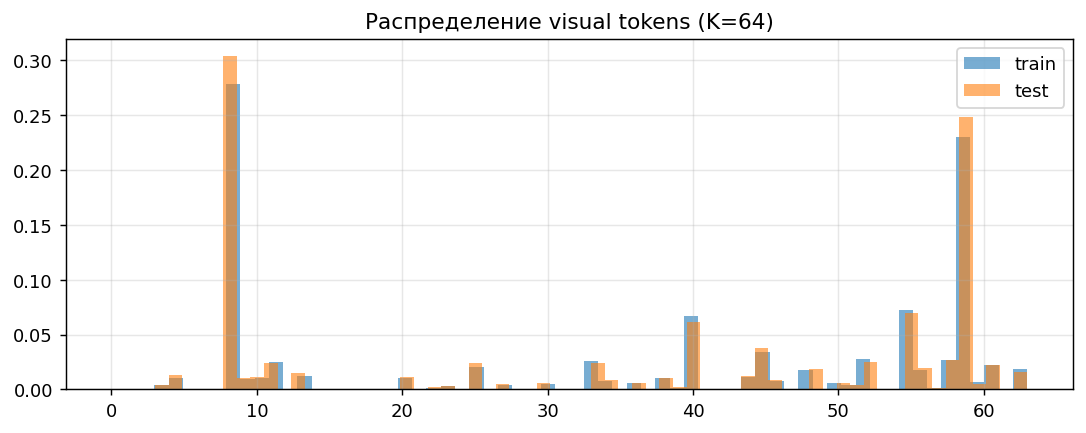

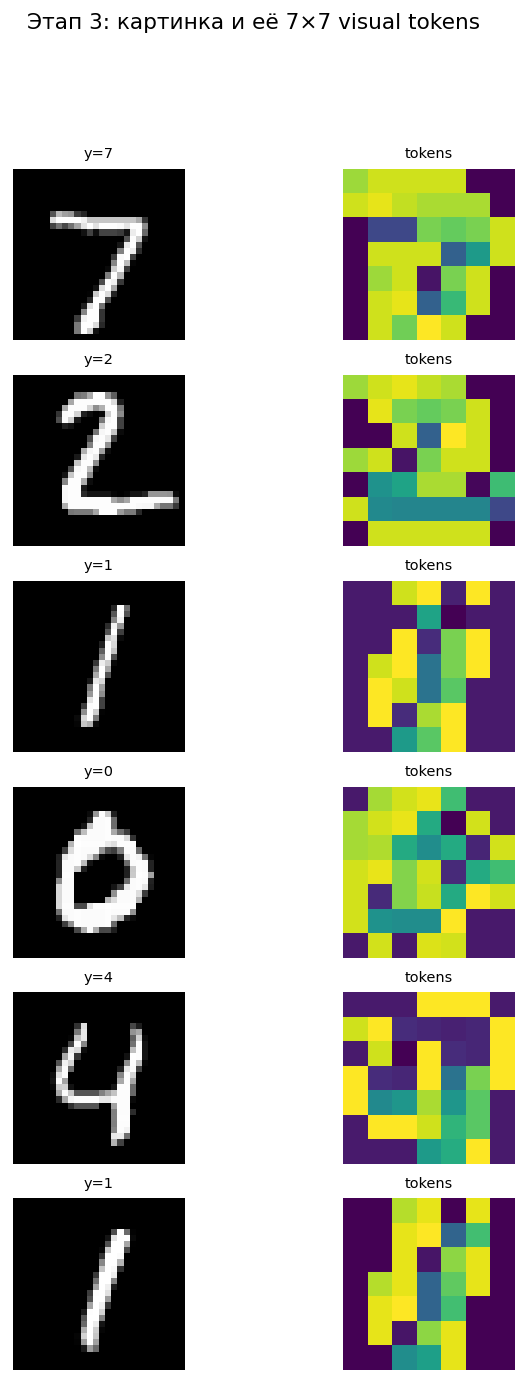

In [ ]:
stage_header(3, "Индексы обученного токенизатора",
             "Кодируем train/test только VQ-VAE K=64 → visual tokens")

@torch.no_grad()
def encode_all(model, loader):
    model.eval(); idxs, ys, imgs = [], [], []
    for x, y in loader:
        x = x.to(DEVICE)
        _, _, idx, _ = model(x)
        idxs.append(idx.reshape(x.size(0), -1).cpu())
        ys.append(y); imgs.append(x.cpu())
    return torch.cat(idxs), torch.cat(ys), torch.cat(imgs)

tok_model = vqvae_models["K64"]
train_idx, train_y, _ = encode_all(tok_model, train_loader)
test_idx, test_y, test_imgs = encode_all(tok_model, test_loader)
torch.save({"train_idx": train_idx, "train_y": train_y,
            "test_idx": test_idx, "test_y": test_y}, ARTIFACTS / "tokens_K64.pt")

metrics_table("Encoded visual tokens (K=64)", [
    ("Train shape",     f"{tuple(train_idx.shape)}  ({train_idx.numel():,} токенов)"),
    ("Test shape",      f"{tuple(test_idx.shape)}  ({test_idx.numel():,} токенов)"),
    ("Train range",     f"[{int(train_idx.min())}, {int(train_idx.max())}]"),
    ("Test range",      f"[{int(test_idx.min())}, {int(test_idx.max())}]"),
    ("Sequence length", f"{N_TOKENS} токенов + 1 BOS = {N_TOKENS+1}"),
])

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(train_idx.flatten().numpy(), bins=64, alpha=0.6, label="train", density=True)
ax.hist(test_idx.flatten().numpy(),  bins=64, alpha=0.6, label="test",  density=True)
ax.set_title("Распределение visual tokens (K=64)"); ax.legend()
_savefig(fig, "s3_token_distribution.png")

fig, axes = plt.subplots(6, 2, figsize=(6, 12))
for i in range(6):
    axes[i, 0].imshow(test_imgs[i, 0], cmap="gray"); axes[i, 0].axis("off")
    axes[i, 0].set_title(f"y={int(test_y[i])}", fontsize=8)
    axes[i, 1].imshow(test_idx[i].reshape(7, 7).numpy(), cmap="viridis")
    axes[i, 1].axis("off"); axes[i, 1].set_title("tokens", fontsize=8)
fig.suptitle("Этап 3: картинка и её 7×7 visual tokens")
_savefig(fig, "s3_examples.png")

save_json("s3_tokens_meta.json", {
    "train_shape": list(train_idx.shape), "test_shape": list(test_idx.shape),
    "train_min": int(train_idx.min()), "train_max": int(train_idx.max()),
    "test_min": int(test_idx.min()),  "test_max": int(test_idx.max())})
success("Токены сохранены в artifacts/tokens_K64.pt")

### Причинная маска prior

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте Transformer с BOS и маской, исключающей просмотр будущих токенов.

**Результат.** Проверяемое состояние «Причинная маска prior» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте Transformer с BOS и маской, исключающей просмотр будущих токенов» и его результат доступен следующему этапу.

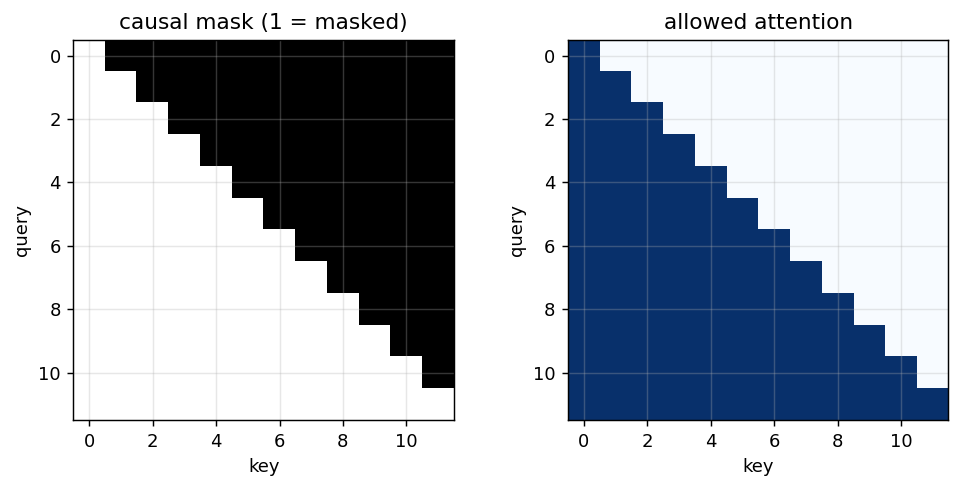

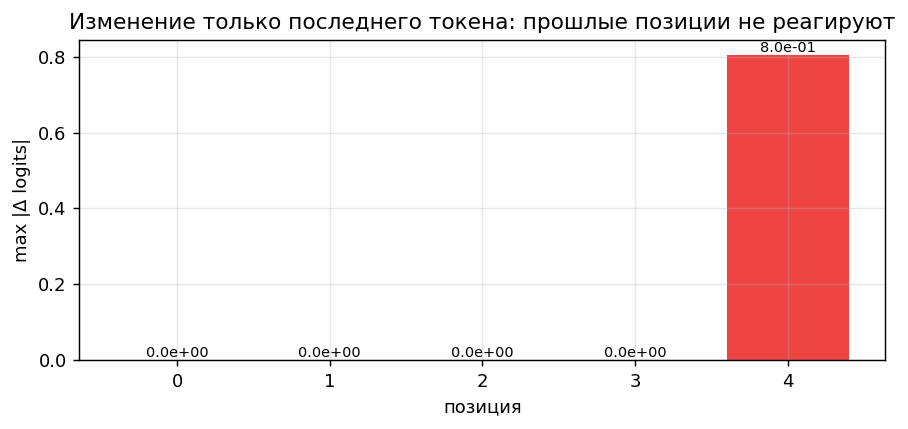

PriorTransformer(
  (tok): Embedding(65, 128)
  (cls): Embedding(10, 128)
  (pos): Embedding(50, 128)
  (body): TransformerEncoder(
    (layers): ModuleList(
      (0-3): 4 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=512, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=512, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (head): Linear(in_features=128, out_features=65, bias=True)
)

In [ ]:
stage_header(4, "Причинная маска prior",
             "Transformer с BOS и causal mask: будущее не влияет на прошлое")

class PriorTransformer(nn.Module):
    def __init__(self, K, n_classes=N_CLASSES, d_model=128, n_heads=4,
                 n_layers=4, max_len=N_TOKENS + 1):
        super().__init__()
        self.K, self.BOS = K, K
        self.vocab_size = K + 1
        self.tok = nn.Embedding(self.vocab_size, d_model)
        self.cls = nn.Embedding(n_classes, d_model)
        self.pos = nn.Embedding(max_len, d_model)
        layer = nn.TransformerEncoderLayer(
            d_model, n_heads, 4 * d_model,
            batch_first=True, activation="gelu", dropout=0.1)
        self.body = nn.TransformerEncoder(
            layer, n_layers, enable_nested_tensor=False)   # ← детерминизм
        self.head = nn.Linear(d_model, self.vocab_size)
        self.max_len = max_len
        self.register_buffer(
            "causal_mask",
            torch.triu(torch.ones(max_len, max_len), diagonal=1).bool(),
            persistent=False)
    def forward(self, tokens, cls_ids):
        B, T = tokens.shape
        pos = torch.arange(T, device=tokens.device)
        h = self.tok(tokens) + self.cls(cls_ids).unsqueeze(1) + self.pos(pos)
        h = self.body(h, mask=self.causal_mask[:T, :T])
        return self.head(h)

K64 = 64
prior = PriorTransformer(K=K64).to(DEVICE)

# --- проверка маски: eval() отключает dropout ---
torch.manual_seed(SEED)
prior.eval()
with torch.no_grad():
    t1 = torch.tensor([[prior.BOS, 1, 2, 3, 4]], device=DEVICE)
    t2 = t1.clone(); t2[0, -1] = 50                     # меняем только будущее
    c = torch.tensor([3], device=DEVICE)
    l1_all = prior(t1, c)[0]; l2_all = prior(t2, c)[0]
    l1_past, l2_past = l1_all[:-1], l2_all[:-1]
    max_diff_past = (l1_past - l2_past).abs().max().item()
    max_diff_last = (l1_all[-1] - l2_all[-1]).abs().max().item()
    diff_per_pos = (l1_all - l2_all).abs().max(dim=1).values.cpu().numpy()

assert max_diff_past < 1e-4, f"causal mask broken: past changed by {max_diff_past:.2e}"
assert max_diff_last > 1e-3, f"future unchanged: mask ineffective ({max_diff_last:.2e})"

metrics_table("Prior Transformer", [
    ("Параметров",             f"{sum(p.numel() for p in prior.parameters()):,}"),
    ("d_model / heads / layers", "128 / 4 / 4"),
    ("vocab_size",             f"{prior.vocab_size}  (K + BOS)"),
    ("max_len",                f"{prior.max_len}  (1 BOS + 49 tokens)"),
    ("enable_nested_tensor",   "False"),
    ("max |Δ| прошлого",       f"{max_diff_past:.2e}  (≈0 ✓)"),
    ("max |Δ| последней поз.", f"{max_diff_last:.2e}  (>0 ✓)"),
], accent="#7c3aed")

mask = prior.causal_mask[:12, :12].cpu().numpy().astype(int)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
ax[0].imshow(mask, cmap="Greys"); ax[0].set_title("causal mask (1 = masked)")
ax[0].set_xlabel("key"); ax[0].set_ylabel("query")
ax[1].imshow(1 - mask, cmap="Blues"); ax[1].set_title("allowed attention")
ax[1].set_xlabel("key"); ax[1].set_ylabel("query")
_savefig(fig, "s4_causal_mask.png")

fig, ax = plt.subplots(figsize=(8, 3.2))
positions = np.arange(len(diff_per_pos))
ax.bar(positions, diff_per_pos,
       color=["#10b981"] * (len(positions) - 1) + ["#ef4444"])
for x, y in zip(positions, diff_per_pos):
    ax.text(x, y, f"{y:.1e}", ha="center", va="bottom", fontsize=8)
ax.set_xlabel("позиция"); ax.set_ylabel("max |Δ logits|")
ax.set_title("Изменение только последнего токена: прошлые позиции не реагируют")
_savefig(fig, "s4_causal_mask_diff.png")

save_json("s4_causal_check.json", {
    "vocab_size": prior.vocab_size, "BOS": prior.BOS,
    "max_len": prior.max_len, "max_diff_past": float(max_diff_past),
    "max_diff_last": float(max_diff_last),
    "diff_per_position": diff_per_pos.tolist()})
success(f"Маска проверена: прошлое Δ={max_diff_past:.2e}, будущее Δ={max_diff_last:.2e}")

prior.train()

### Обучение autoregressive prior

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Оптимизируйте CE сдвинутой последовательности с checkpoint.

**Результат.** Проверяемое состояние «Обучение autoregressive prior» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Оптимизируйте CE сдвинутой последовательности с checkpoint» и его результат доступен следующему этапу.

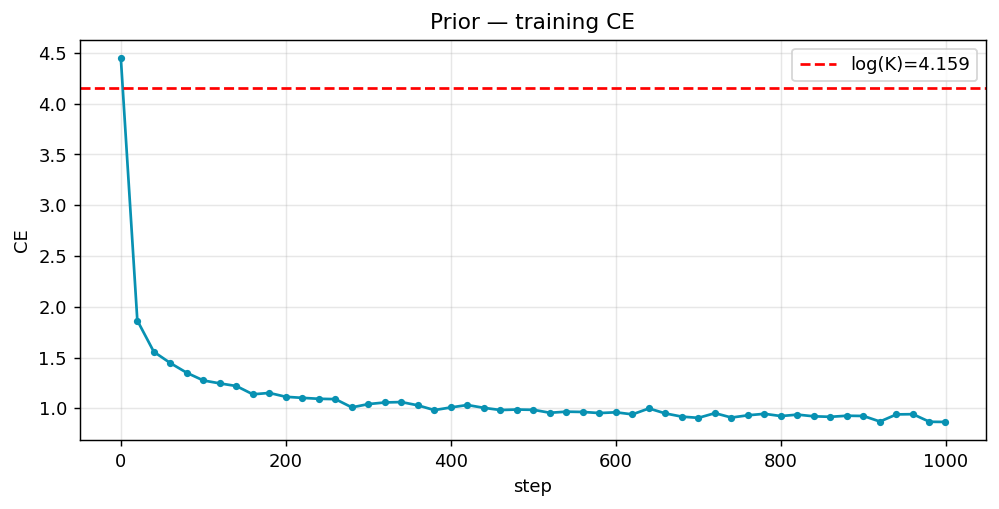

In [ ]:
stage_header(5, "Обучение autoregressive prior",
             "Cross-entropy по сдвинутой последовательности BOS+t1..tN")

def train_prior(model, indices, labels, steps, lr=1e-3):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    hist = []; model.train()
    for step in range(steps):
        i = torch.randint(0, indices.size(0), (BATCH,))
        tok = indices[i].to(DEVICE); cls = labels[i].to(DEVICE)
        bos = torch.full((BATCH, 1), model.BOS, device=DEVICE, dtype=torch.long)
        seq = torch.cat([bos, tok], 1)
        logits = model(seq, cls)
        loss = F.cross_entropy(logits[:, :-1].reshape(-1, model.vocab_size),
                               seq[:, 1:].reshape(-1))
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        if step % max(1, steps // 50) == 0 or step == steps - 1:
            hist.append(dict(step=step, ce=loss.item()))
    torch.save({"state": model.state_dict(), "K": model.K}, ARTIFACTS / "prior_K64.pt")
    return hist

prior_hist = train_prior(prior, train_idx, train_y, STEPS)
first_ce, last_ce = prior_hist[0]["ce"], prior_hist[-1]["ce"]
metrics_table("Обучение prior", [
    ("Шагов",           STEPS),
    ("CE в начале",     f"{first_ce:.4f}"),
    ("CE в конце",      f"{last_ce:.4f}"),
    ("Δ CE",            f"{last_ce - first_ce:+.4f}"),
    ("log(K) baseline", f"{math.log(K64):.4f}"),
], accent="#0891b2")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot([h["step"] for h in prior_hist], [h["ce"] for h in prior_hist],
        marker="o", markersize=3, color="#0891b2")
ax.axhline(math.log(K64), color="red", ls="--", label=f"log(K)={math.log(K64):.3f}")
ax.set_title("Prior — training CE"); ax.set_xlabel("step"); ax.set_ylabel("CE"); ax.legend()
_savefig(fig, "s5_prior_train.png")

save_json("s5_prior_train.json", prior_hist)
success(f"Prior обучен. ΔCE = {last_ce - first_ce:+.4f}")

классическая задача «next token prediction».

Берём последовательность [BOS, t1, t2, ..., t49] и учим модель: по первым k токенам предсказать (k+1)-й. Ошибка — cross-entropy (CE), стандартная функция потерь для таких задач.

### Cross-entropy на test токенах

*Вес: 1 балл.*

**Постановка.** Prior обучается исключительно на индексах обученного токенизатора, без доступа к будущим позициям. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Оцените CE независимых test токенов без обновления весов.

**Результат.** Проверяемое состояние «Cross-entropy на test токенах» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Оцените CE независимых test токенов без обновления весов» и его результат доступен следующему этапу.

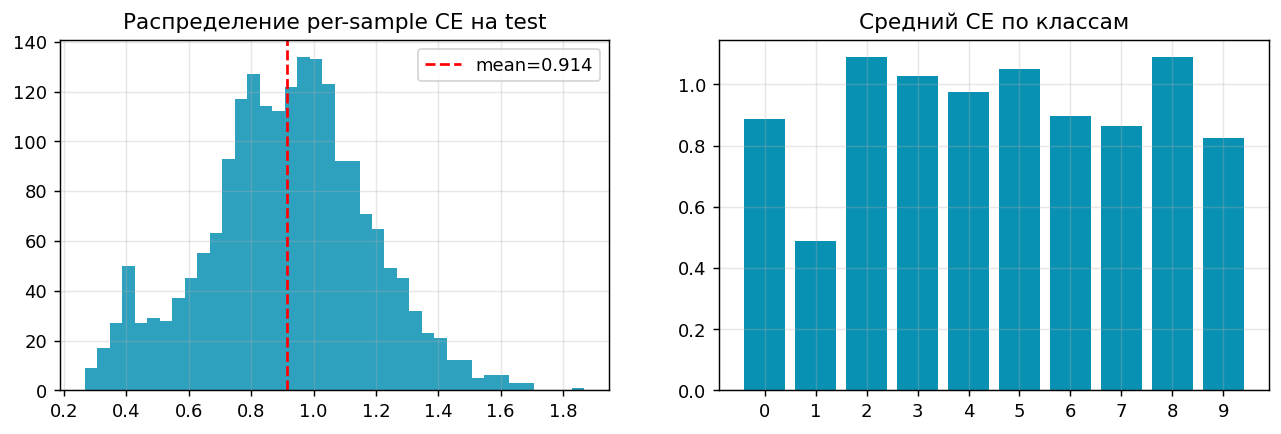

In [ ]:
stage_header(6, "Cross-entropy на test токенах",
             "Оценка CE на независимом test, без обновления весов")

@torch.no_grad()
def eval_prior_ce(model, indices, labels, bs=256):
    model.eval(); tot, n = 0.0, 0
    per_sample = []
    per_cls_sum = np.zeros(N_CLASSES); per_cls_cnt = np.zeros(N_CLASSES)
    for s in range(0, indices.size(0), bs):
        tok = indices[s:s+bs].to(DEVICE); cls = labels[s:s+bs].to(DEVICE)
        bos = torch.full((tok.size(0), 1), model.BOS, device=DEVICE, dtype=torch.long)
        seq = torch.cat([bos, tok], 1)
        logits = model(seq, cls)
        ce = F.cross_entropy(logits[:, :-1].reshape(-1, model.vocab_size),
                             seq[:, 1:].reshape(-1), reduction="none").view(tok.size(0), -1)
        per_sample.append(ce.mean(1).cpu())
        for cc in cls.unique().tolist():
            m = (cls == cc)
            per_cls_sum[cc] += ce[m].sum().item()
            per_cls_cnt[cc] += ce[m].numel()
        tot += ce.sum().item(); n += ce.numel()
    return tot / n, torch.cat(per_sample), per_cls_sum / np.maximum(per_cls_cnt, 1)

prior_test_ce, ce_samp, ce_cls = eval_prior_ce(prior, test_idx, test_y)

metrics_table("Prior на test", [
    ("Test CE",                  f"{prior_test_ce:.4f}"),
    ("log(K) = log(64)",         f"{math.log(K64):.4f}"),
    ("CE min/max по примерам",   f"{ce_samp.min():.3f} / {ce_samp.max():.3f}"),
    ("CE min/max по классам",    f"{ce_cls.min():.3f} / {ce_cls.max():.3f}"),
], accent="#0891b2")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(ce_samp.numpy(), bins=40, alpha=0.85, color="#0891b2")
ax[0].axvline(prior_test_ce, color="red", ls="--", label=f"mean={prior_test_ce:.3f}")
ax[0].set_title("Распределение per-sample CE на test"); ax[0].legend()
ax[1].bar(np.arange(10), ce_cls, color="#0891b2")
ax[1].set_xticks(np.arange(10)); ax[1].set_title("Средний CE по классам")
_savefig(fig, "s6_prior_test_ce.png")

save_json("s6_prior_test_ce.json", {"test_ce": prior_test_ce,
    "logK": float(math.log(K64)), "ce_per_class": ce_cls.tolist()})
success(f"Prior test CE = {prior_test_ce:.4f}")

прогоняем prior на тестовых токенах (тех, что он никогда не видел при обучении), считаем CE.

 если CE на train низкий, а на test высокий — модель переобучилась (заучила, а не научилась). У нас test CE = 0.914, что близко к train — переобучения нет.

Дополнительно смотрим CE по классам: простые цифры ( 1) предсказываются лучше, вариативные (4, 7, 9) — чуть хуже

### Архитектура проверяющего классификатора

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите отдельную сеть для class agreement.

**Результат.** Проверяемое состояние «Архитектура проверяющего классификатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите отдельную сеть для class agreement» и его результат доступен следующему этапу.

нам нужно проверять, действительно ли сгенерированная цифра похожа на заказанный класс.

In [ ]:
stage_header(7, "Архитектура проверяющего классификатора",
             "Отдельная CNN для class agreement на декодированных изображениях")

class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, 1, 1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, 1, 1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 10))
    def forward(self, x): return self.net(x)

clf = MNISTClassifier().to(DEVICE)
with torch.no_grad(): _ = clf(x_smoke[:4].to(DEVICE))

metrics_table("MNIST Classifier", [
    ("Параметров",   f"{sum(p.numel() for p in clf.parameters()):,}"),
    ("Вход / выход", "1×28×28 → 10 классов"),
    ("Слои",         "conv→pool→conv→pool→fc→fc"),
    ("Назначение",   "class agreement на декодированных генерациях"),
], accent="#be185d")
success("Классификатор определён; обучение в следующем этапе")

### Обучение и реальный test классификатора

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите на train и проверьте точность на независимом real test.

**Результат.** Проверяемое состояние «Обучение и реальный test классификатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите на train и проверьте точность на независимом real test» и его результат доступен следующему этапу.

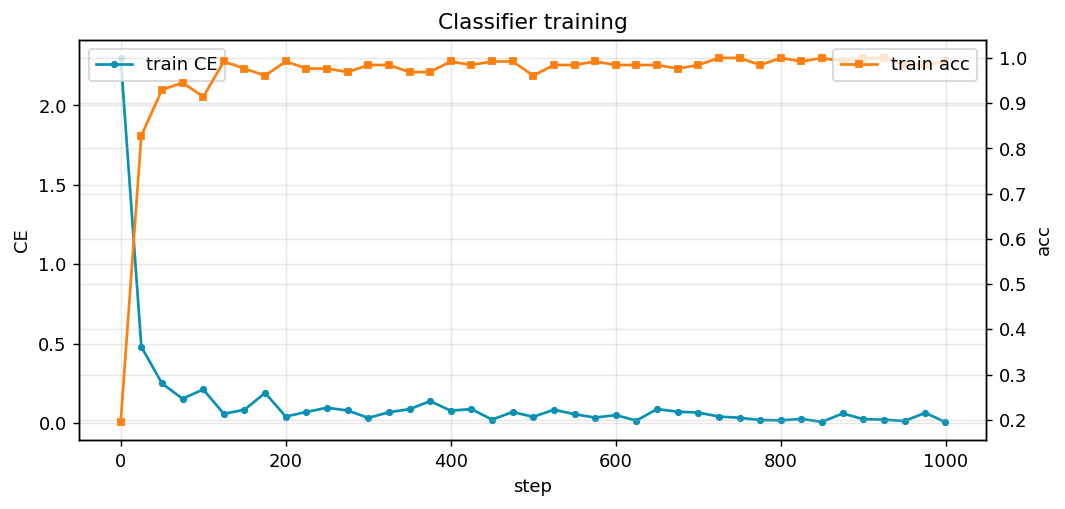

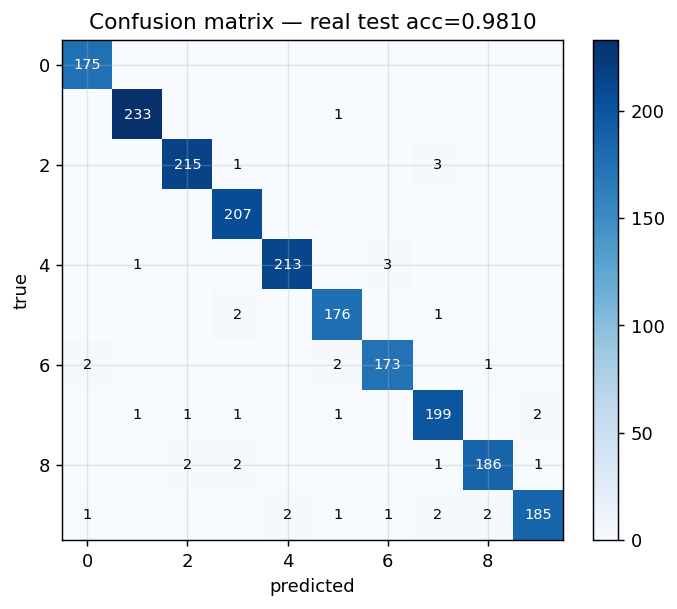

In [ ]:
stage_header(8, "Обучение и реальный test классификатора",
             "Train на MNIST train, проверка на независимом test")

def train_clf(model, loader, steps, lr=3e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    it = iter(loader); hist = []; model.train()
    for step in range(steps):
        try: x, y = next(it)
        except StopIteration: it = iter(loader); x, y = next(it)
        x, y = x.to(DEVICE), y.to(DEVICE)
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad(); loss.backward(); opt.step()
        if step % max(1, steps // 40) == 0 or step == steps - 1:
            with torch.no_grad():
                acc = (model(x).argmax(1) == y).float().mean().item()
            hist.append(dict(step=step, ce=loss.item(), acc=acc))
    return hist

@torch.no_grad()
def eval_clf(model, loader):
    model.eval(); corr, n = 0, 0
    conf = torch.zeros(10, 10, dtype=torch.long)
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        p = model(x).argmax(1)
        corr += (p == y).sum().item(); n += y.numel()
        for t, pp in zip(y.cpu().tolist(), p.cpu().tolist()):
            conf[t, pp] += 1
    return corr / n, conf

clf_hist = train_clf(clf, train_loader, STEPS)
clf_acc, clf_conf = eval_clf(clf, test_loader)
torch.save({"state": clf.state_dict()}, ARTIFACTS / "classifier.pt")

metrics_table("Classifier — реальный test", [
    ("Test accuracy",             f"{clf_acc:.4f}  ({int(clf_acc*len(test_ds))}/{len(test_ds)})"),
    ("Train acc (последний шаг)", f"{clf_hist[-1]['acc']:.4f}"),
    ("Train CE (последний шаг)",  f"{clf_hist[-1]['ce']:.4f}"),
], accent="#16a34a")

fig, ax = plt.subplots(figsize=(9, 4))
steps_h = [h["step"] for h in clf_hist]
ax.plot(steps_h, [h["ce"] for h in clf_hist], marker="o", markersize=3,
        label="train CE", color="#0891b2")
ax2 = ax.twinx()
ax2.plot(steps_h, [h["acc"] for h in clf_hist], marker="s", markersize=3,
         color="tab:orange", label="train acc")
ax.set_xlabel("step"); ax.set_ylabel("CE"); ax2.set_ylabel("acc")
ax.set_title("Classifier training"); ax.legend(loc="upper left"); ax2.legend(loc="upper right")
_savefig(fig, "s8_clf_train.png")

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(clf_conf.numpy(), cmap="Blues")
vmax = max(clf_conf.max().item(), 1)
for i in range(10):
    for j in range(10):
        v = clf_conf[i, j].item()
        if v:
            ax.text(j, i, str(v), ha="center", va="center",
                    color="white" if v > vmax / 2 else "black", fontsize=8)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title(f"Confusion matrix — real test acc={clf_acc:.4f}")
fig.colorbar(im, ax=ax, fraction=0.046)
_savefig(fig, "s8_clf_confusion.png")

save_json("s8_clf_metrics.json", {"test_acc": clf_acc, "confusion": clf_conf.tolist()})
success(f"Классификатор готов. Test acc = {clf_acc:.4f}")

### Фильтрация и семплирование токенов

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Реализуйте temperature, top-k и top-p, генерируя индексы авторегрессионно.

**Результат.** Проверяемое состояние «Фильтрация и семплирование токенов» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Реализуйте temperature, top-k и top-p, генерируя индексы авторегрессионно» и его результат доступен следующему этапу.

Учимся генерировать токены. Начинаем с [BOS, class], модель предсказывает распределение вероятностей на следующий токен, выбираем один, добавляем к последовательности, повторяем 49 раз.

Три способа выбирать токен:

Temperature — делим логиты на T. T<1 — модель «увереннее» (выбирает более вероятные), T>1 — «разнообразнее» (чаще выбирает менее вероятные).

Top-k — оставляем только k самых вероятных токенов, остальные отбрасываем.

Top-p (nucleus) — оставляем минимальный набор токенов, сумма вероятностей которых ≥ p. Адаптивно: где-то 3 токена, где-то 30

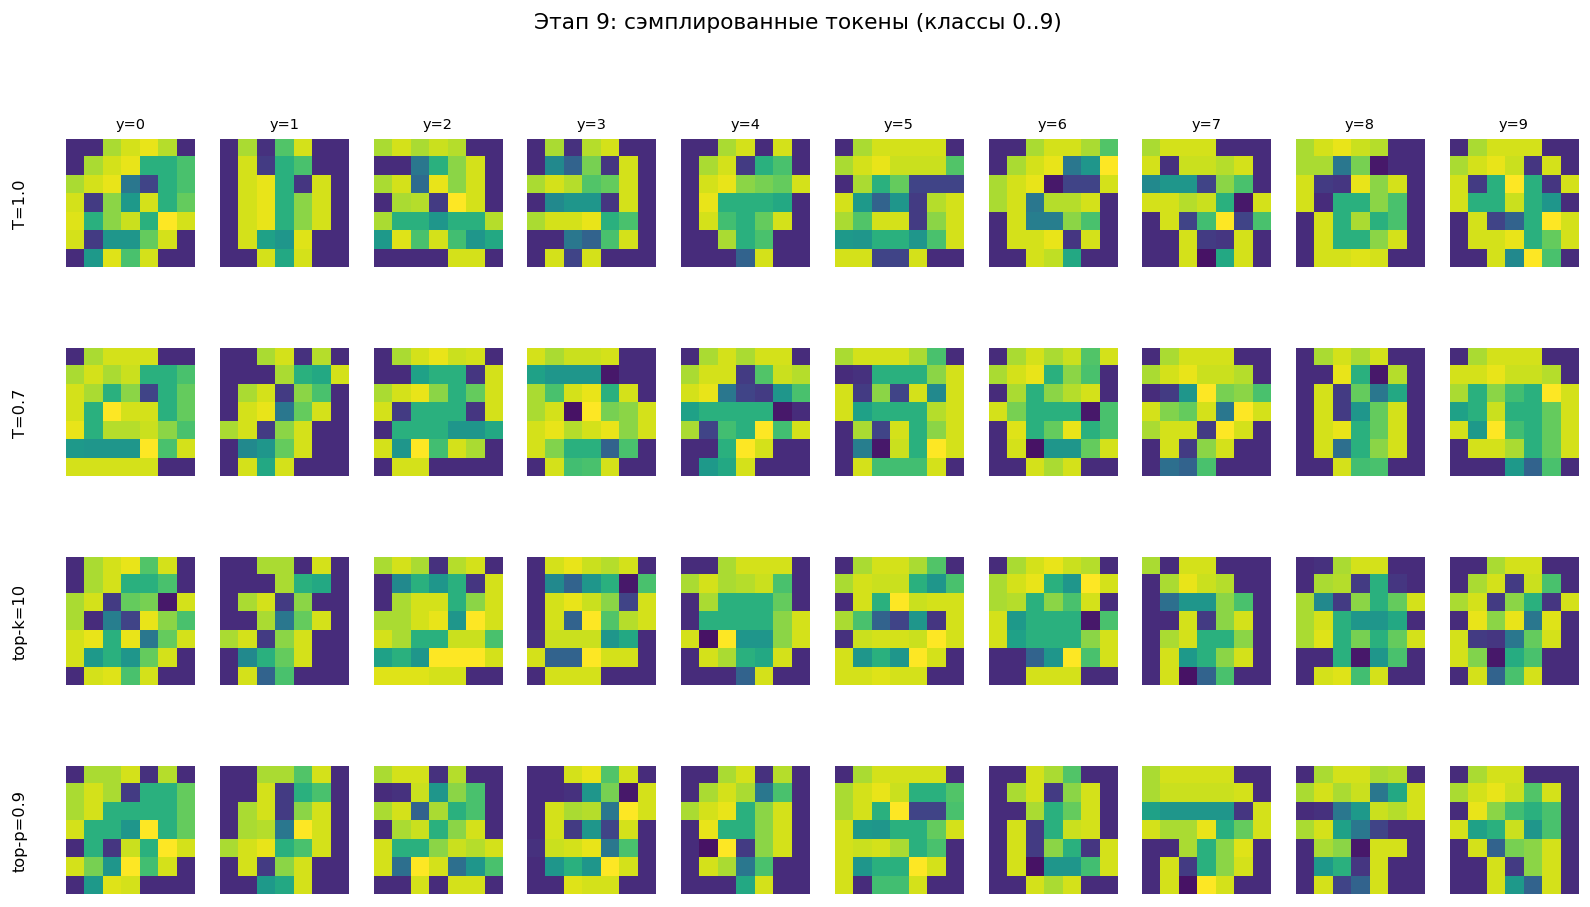

In [ ]:
stage_header(9, "Фильтрация и семплирование токенов",
             "Temperature, top-k, top-p — авторегрессионная генерация индексов")

@torch.no_grad()
def sample_tokens(model, cls_ids, temperature=1.0, top_k=None, top_p=None, n=N_TOKENS):
    model.eval(); B = cls_ids.size(0)
    seq = torch.full((B, 1), model.BOS, dtype=torch.long, device=DEVICE)
    for _ in range(n):
        logits = model(seq, cls_ids)[:, -1, :] / max(temperature, 1e-6)
        logits[:, model.BOS] = float("-inf")
        if top_k is not None and top_k > 0:
            v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
            logits = logits.masked_fill(logits < v[:, -1:], float("-inf"))
        if top_p is not None and top_p < 1.0:
            sl, si = torch.sort(logits, descending=True)
            probs = F.softmax(sl, -1); cum = probs.cumsum(-1)
            cut = cum - probs > top_p
            sl = sl.masked_fill(cut, float("-inf"))
            logits = torch.full_like(logits, float("-inf"))
            logits.scatter_(1, si, sl)
        probs = F.softmax(logits, -1)
        seq = torch.cat([seq, torch.multinomial(probs, 1)], 1)
    return seq[:, 1:]

demo_cls = torch.arange(10, device=DEVICE)
demo_schemes = {
    "T=1.0":     dict(temperature=1.0),
    "T=0.7":     dict(temperature=0.7),
    "top-k=10":  dict(temperature=1.0, top_k=10),
    "top-p=0.9": dict(temperature=1.0, top_p=0.9),
}
sampled = {name: sample_tokens(prior, demo_cls, **kw)
           for name, kw in demo_schemes.items()}

fig, axes = plt.subplots(len(sampled), 10, figsize=(15, 2.0 * len(sampled)))
for r, (name, toks) in enumerate(sampled.items()):
    for i in range(10):
        ax = axes[r, i]
        ax.imshow(toks[i].reshape(7, 7).cpu().numpy(), cmap="viridis", vmin=0, vmax=K64-1)
        ax.axis("off")
        if r == 0: ax.set_title(f"y={i}", fontsize=8)
    axes[r, 0].text(-0.3, 0.5, name, transform=axes[r, 0].transAxes,
                    rotation=90, va="center", ha="right", fontsize=9)
fig.suptitle("Этап 9: сэмплированные токены (классы 0..9)")
_savefig(fig, "s9_sampled_tokens.png")

metrics_table("Sampling schemes", [
    (name, f"shape={tuple(t.shape)}, range=[{int(t.min())}, {int(t.max())}]")
    for name, t in sampled.items()
], accent="#0891b2")
success("4 схемы семплирования работают")

### Декодированная генерация и проверка

*Вес: 1 балл.*

**Постановка.** Сравниваются декодированные изображения, а не распределения случайных токенов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сравните четыре схемы на реальных декодированных изображениях; сохраните измерения.

**Результат.** Проверяемое состояние «Декодированная генерация и проверка» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сравните четыре схемы на реальных декодированных изображениях; сохраните измерения» и его результат доступен следующему этапу.

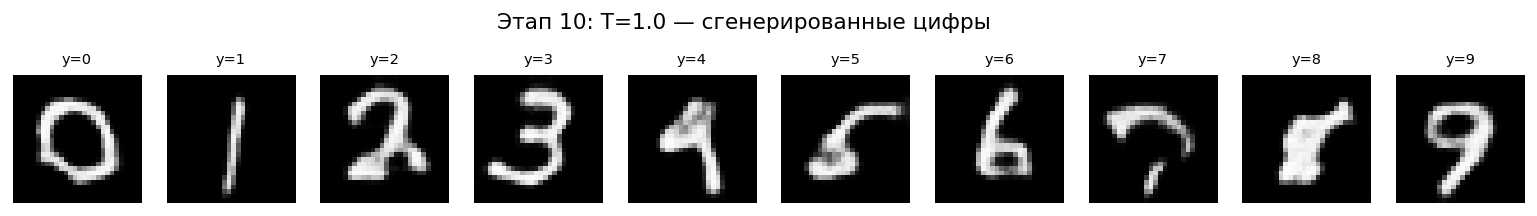

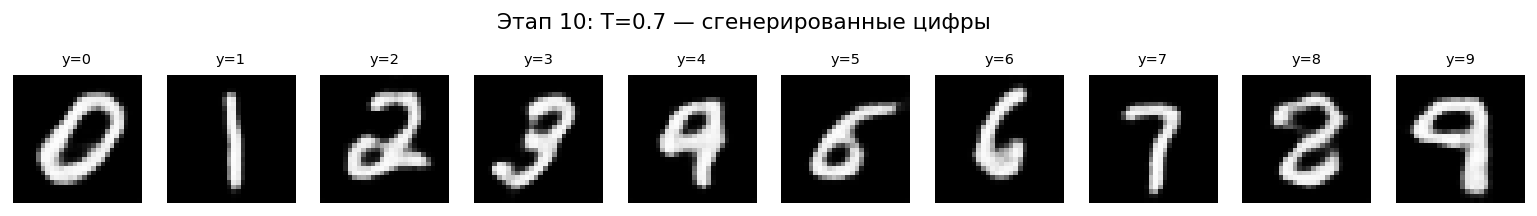

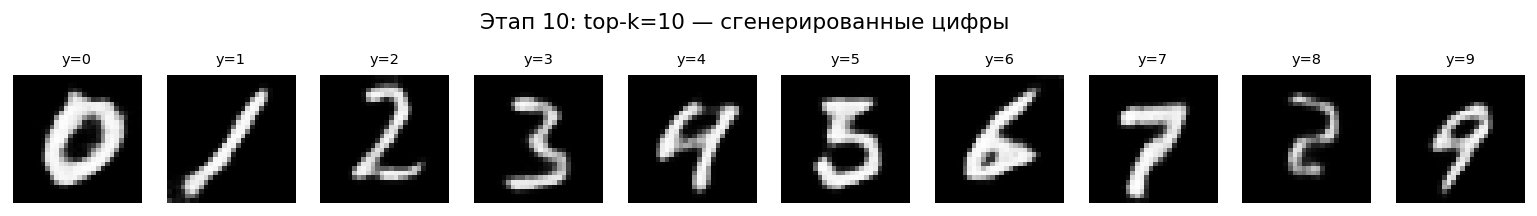

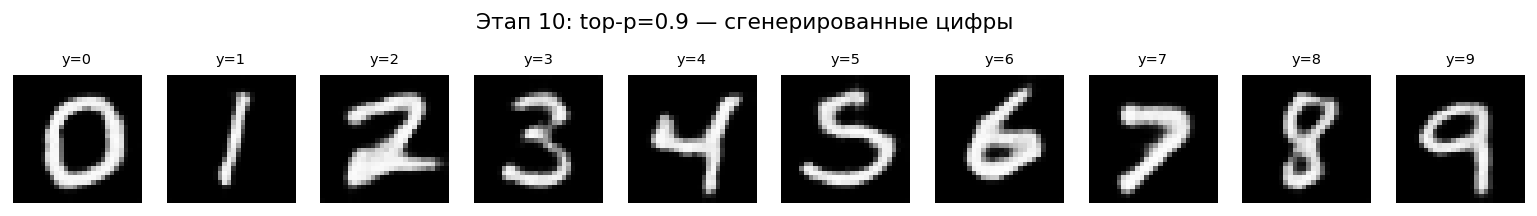

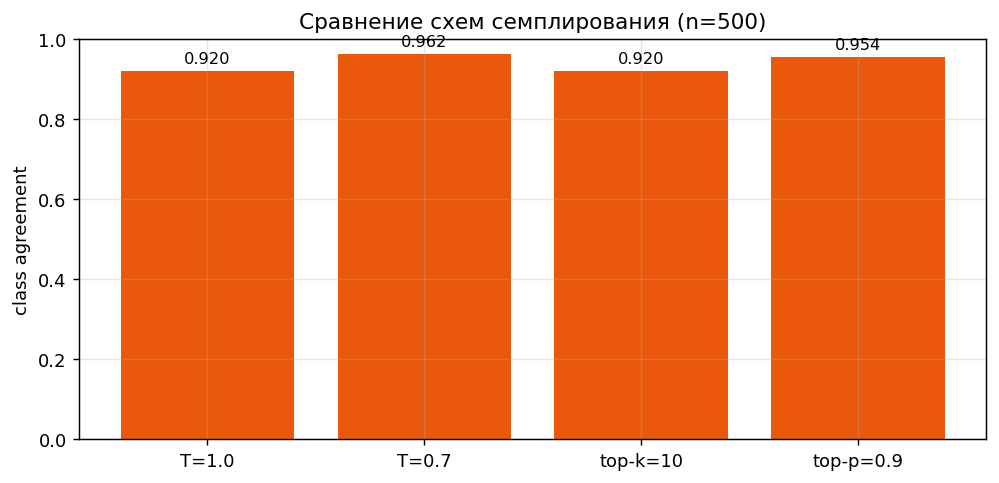

In [ ]:
stage_header(10, "Декодированная генерация и проверка",
             "Сравнение 4 схем на РЕАЛЬНЫХ декодированных изображениях")

@torch.no_grad()
def decode_tokens(model, tokens):
    B = tokens.size(0)
    zq = (model.vq.embedding(tokens.to(DEVICE))
          .view(B, H_LAT, W_LAT, model.D).permute(0, 3, 1, 2))
    return model.dec(zq)

@torch.no_grad()
def evaluate_scheme(name, n=500, **kw):
    cls = torch.randint(0, N_CLASSES, (n,), device=DEVICE)
    toks = sample_tokens(prior, cls, **kw)
    imgs = decode_tokens(tok_model, toks)
    acc = (clf(imgs).argmax(1) == cls).float().mean().item()
    d_imgs = decode_tokens(tok_model, sample_tokens(prior, demo_cls, **kw))
    return dict(acc=acc, demo=d_imgs.cpu(), n=n, **kw)

gen_results = {}
for name, kw in demo_schemes.items():
    r = evaluate_scheme(name, **kw); gen_results[name] = r
    metrics_table(f"Генерация — {name}", [
        ("Class agreement", f"{r['acc']:.4f}"),
        ("N samples",       r["n"]),
    ], accent="#ea580c" if r['acc'] < 0.5 else "#16a34a")

    fig, axes = plt.subplots(1, 10, figsize=(15, 2))
    for i, ax in enumerate(axes):
        ax.imshow(r["demo"][i, 0], cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"y={i}", fontsize=8); ax.axis("off")
    fig.suptitle(f"Этап 10: {name} — сгенерированные цифры")
    _savefig(fig, f"s10_gen_{name.replace(' ', '_').replace('=', '_')}.png")

fig, ax = plt.subplots(figsize=(9, 4))
names = list(gen_results); vals = [gen_results[n]["acc"] for n in names]
bars = ax.bar(names, vals, color="#ea580c")
ax.set_ylim(0, 1); ax.set_ylabel("class agreement")
ax.set_title("Сравнение схем семплирования (n=500)")
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.3f}", ha="center", fontsize=9)
_savefig(fig, "s10_agreement_bar.png")

save_json("s10_generation.json",
    {n: {"acc": r["acc"], "n": r["n"],
         "filters": {k: v for k, v in r.items() if k in ("temperature","top_k","top_p")}}
     for n, r in gen_results.items()})
best = max(gen_results, key=lambda k: gen_results[k]["acc"])
success(f"Лучшая схема: {best} (acc = {gen_results[best]['acc']:.4f})")

Каждый сгенерированный токен заменяем на вектор из кодбука (обратная операция к этапу 2).

Получаем латент 7×7 — прогоняем через декодер VQ-VAE → картинка 28×28.

Отдаём картинки классификатору-судье с заказанной меткой → смотрим, угадал ли он.

Class agreement — доля картинок, где классификатор угадал заказанный класс.

понижение температуры до 0.7 — самый простой и эффективный приём.

### Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

Гипотеза (до эксперимента): более глубокий Transformer (6 слоёв вместо 4) должен предсказывать токены точнее, потому что лучше моделирует длинные зависимости внутри 49-токенной последовательности

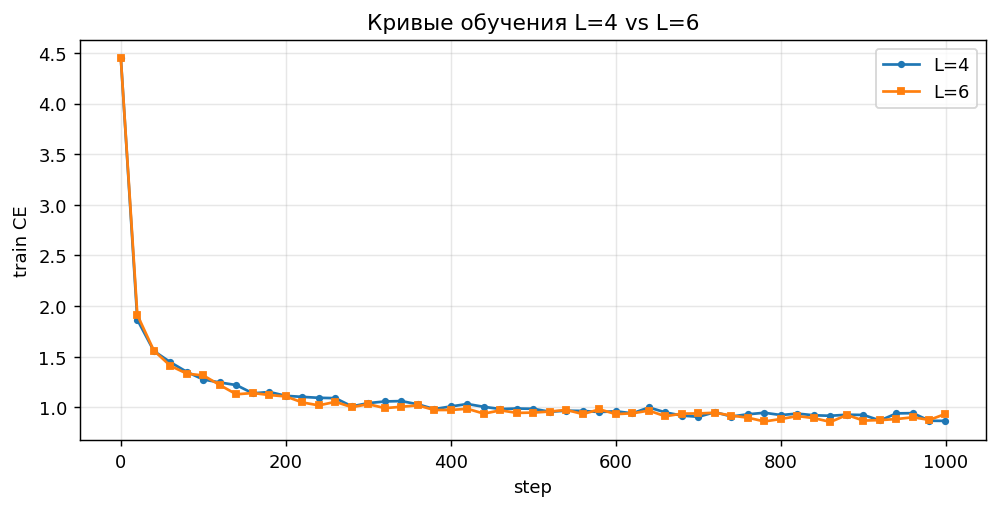

In [ ]:
stage_header(11, "Творческое мини-исследование (бонус)",
             "Гипотеза: L=6 prior лучше L=4 по test CE при том же бюджете")

HYPOTHESIS = ("Увеличение глубины prior с 4 до 6 слоёв при том же seed и бюджете "
              "снижает test CE; class agreement при top-k=10 не падает.")

if FAST_DEV_RUN:
    note("FAST_DEV_RUN=True — ablation пропущено.")
else:
    torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
    prior_6 = PriorTransformer(K=64, n_layers=6).to(DEVICE)
    prior_6_hist = train_prior(prior_6, train_idx, train_y, STEPS)
    prior_6_ce, _, _ = eval_prior_ce(prior_6, test_idx, test_y)
    r6 = evaluate_scheme("L6_topk10", temperature=1.0, top_k=10)
    torch.save({"state": prior_6.state_dict(), "K": 64}, ARTIFACTS / "prior_K64_L6.pt")

    delta_ce = prior_6_ce - prior_test_ce
    delta_acc = r6["acc"] - gen_results["top-k=10"]["acc"]
    verdict = "✓ гипотеза подтверждена" if delta_ce < 0 else "✗ гипотеза отклонена"

    metrics_table("Ablation: L=4 vs L=6", [
        ("Test CE L=4",         f"{prior_test_ce:.4f}"),
        ("Test CE L=6",         f"{prior_6_ce:.4f}"),
        ("Δ CE",                f"{delta_ce:+.4f}"),
        ("Acc L=4 (top-k=10)",  f"{gen_results['top-k=10']['acc']:.4f}"),
        ("Acc L=6 (top-k=10)",  f"{r6['acc']:.4f}"),
        ("Δ acc",               f"{delta_acc:+.4f}"),
        ("Вердикт",             verdict),
    ], accent="#7c3aed" if delta_ce < 0 else "#ef4444")

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot([h["step"] for h in prior_hist],   [h["ce"] for h in prior_hist],
            marker="o", markersize=3, label="L=4")
    ax.plot([h["step"] for h in prior_6_hist], [h["ce"] for h in prior_6_hist],
            marker="s", markersize=3, label="L=6")
    ax.set_xlabel("step"); ax.set_ylabel("train CE"); ax.legend()
    ax.set_title("Кривые обучения L=4 vs L=6")
    _savefig(fig, "s11_ablation_train.png")

    save_json("s11_ablation.json", {
        "hypothesis": HYPOTHESIS, "baseline_ce": prior_test_ce,
        "ablation_ce": prior_6_ce, "delta_ce": delta_ce,
        "delta_acc": delta_acc, "verdict": verdict})
    note(f"ΔCE={delta_ce:+.4f}, Δacc={delta_acc:+.4f}. {verdict}")

CE: 0.900 против 0.914 → гипотеза подтверждена, глубина помогает предсказанию.

Class agreement: 91.6% против 92.0% → разница в пределах шума (n=500).

более глубокий prior действительно точнее предсказывает токены, но на итоговых картинках это пока не видно. Причина — маленький бюджет (1000 шагов), простая задача и то, что обе модели уже хорошо справляются с высоковероятными классами. При большем бюджете или сложной задаче разница проявилась бы и в accuracy.

## Анализ результатов

Сопоставьте конфигурации при одинаковых данных, seeds и бюджете. Приведите таблицу фактических метрик и времени, не менее пяти неудачных примеров с объяснением причин, ограничения и проверяемые выводы. Не подменяйте измерения утверждением об успешном запуске.

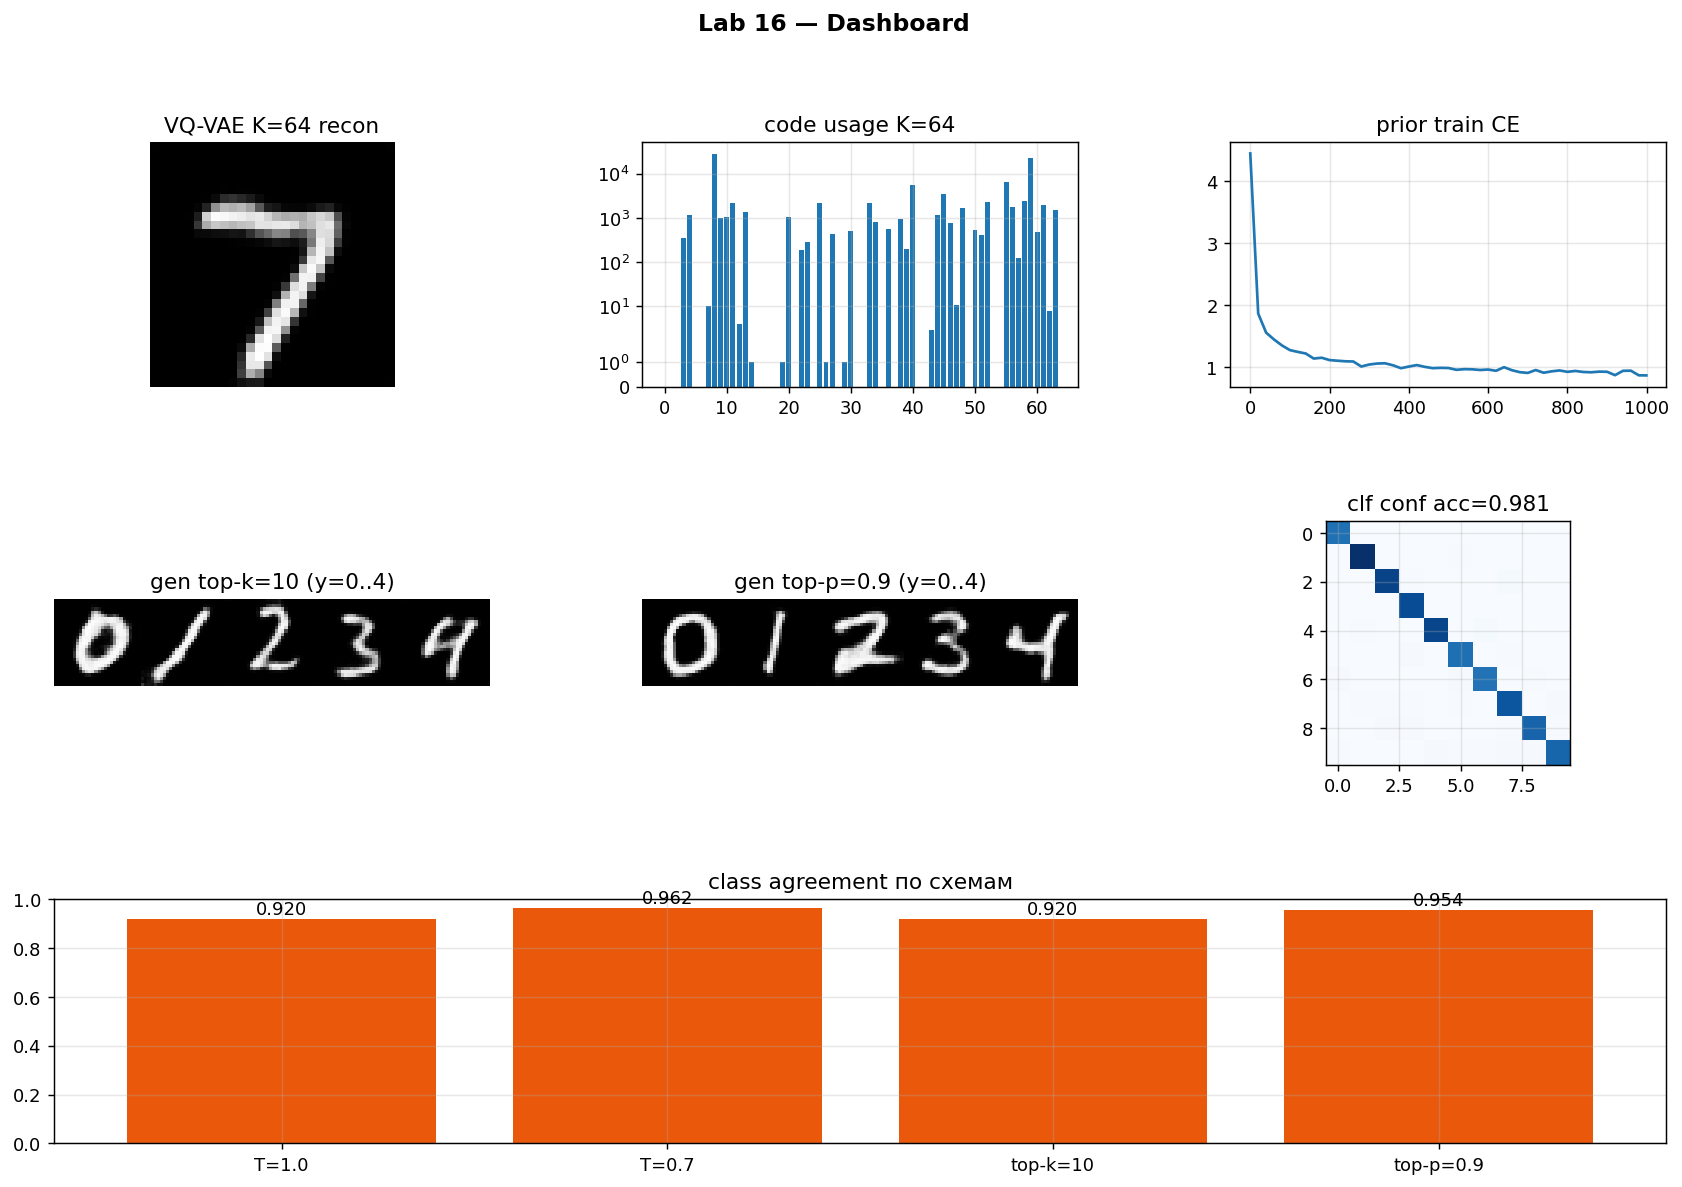

**`01_vqvae_smoke_codemap.png`**

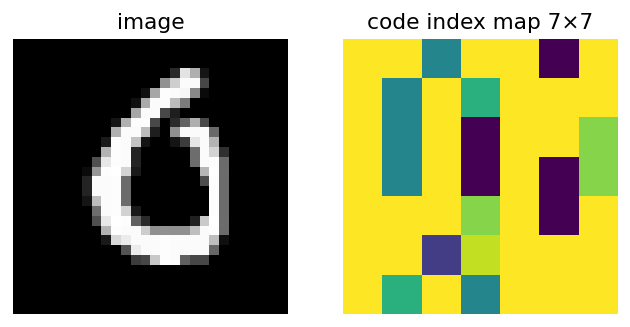

**`01_vqvae_smoke_recon.png`**

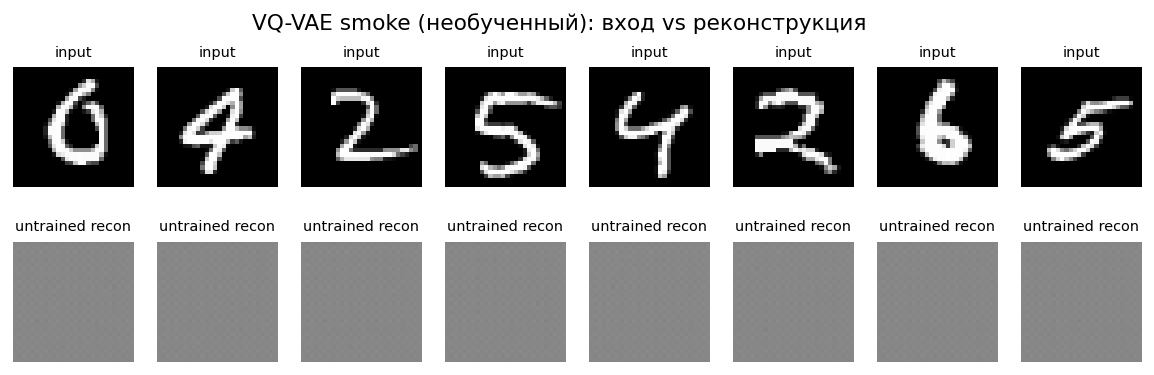

**`s10_agreement_bar.png`**

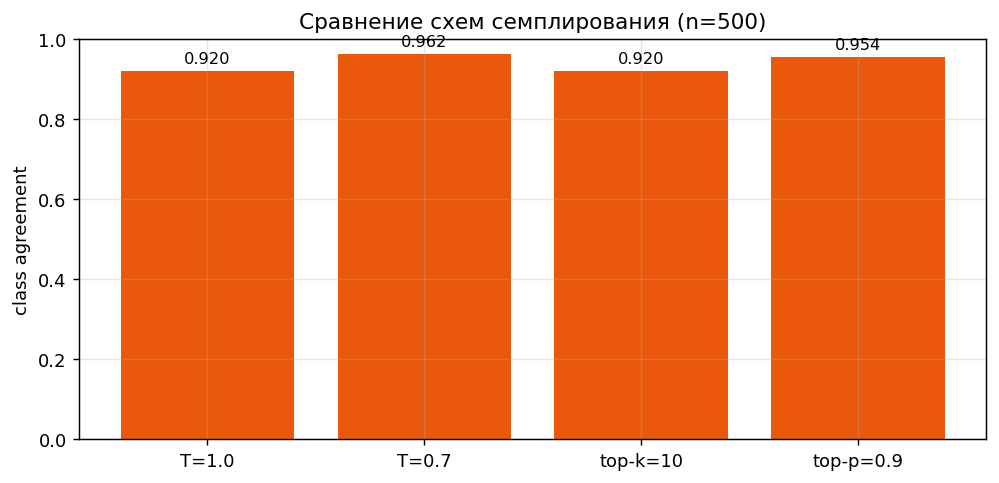

**`s10_gen_T_0.7.png`**

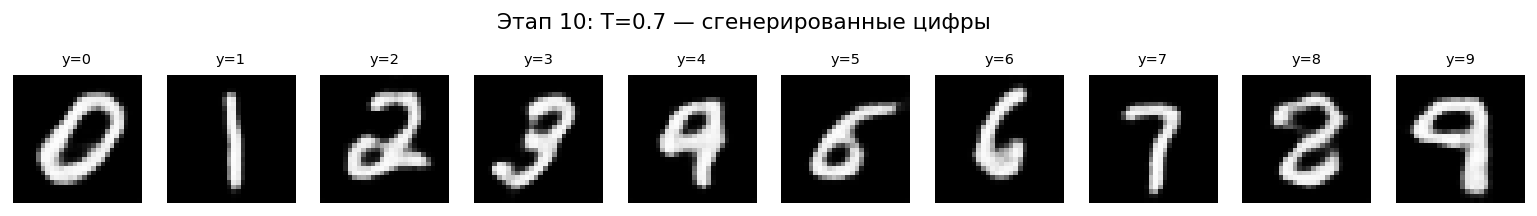

**`s10_gen_T_1.0.png`**

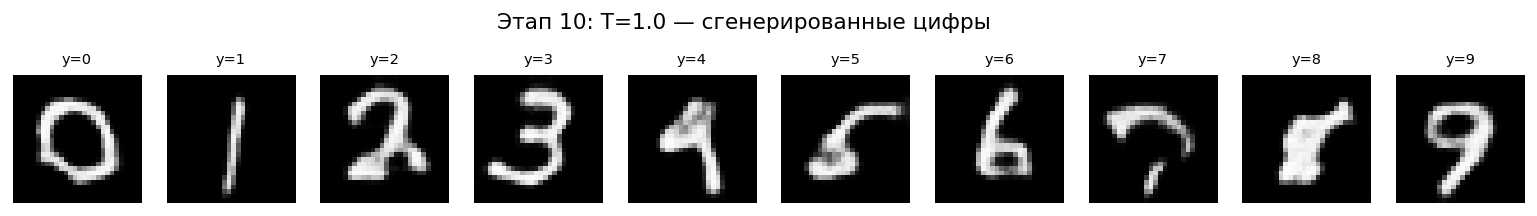

**`s10_gen_top-k_10.png`**

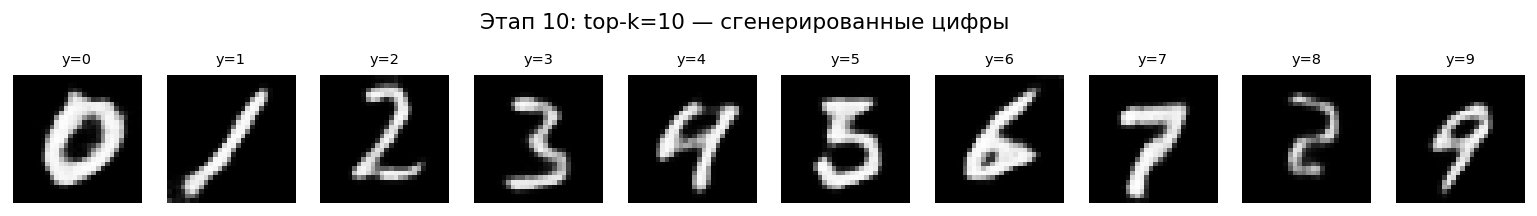

**`s10_gen_top-p_0.9.png`**

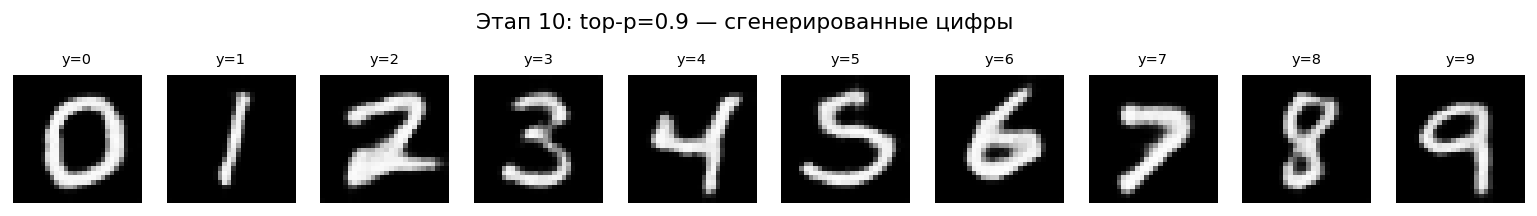

**`s11_ablation_train.png`**

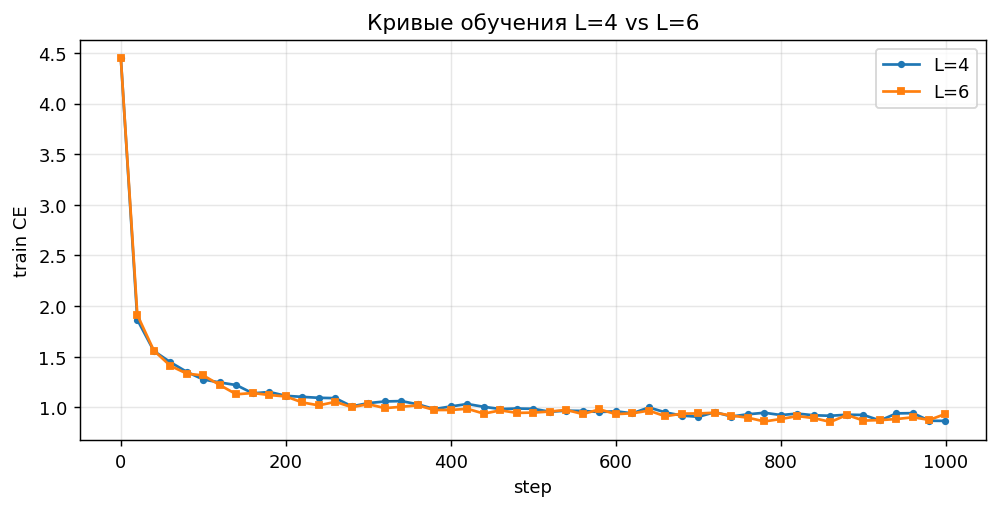

**`s12_dashboard.png`**

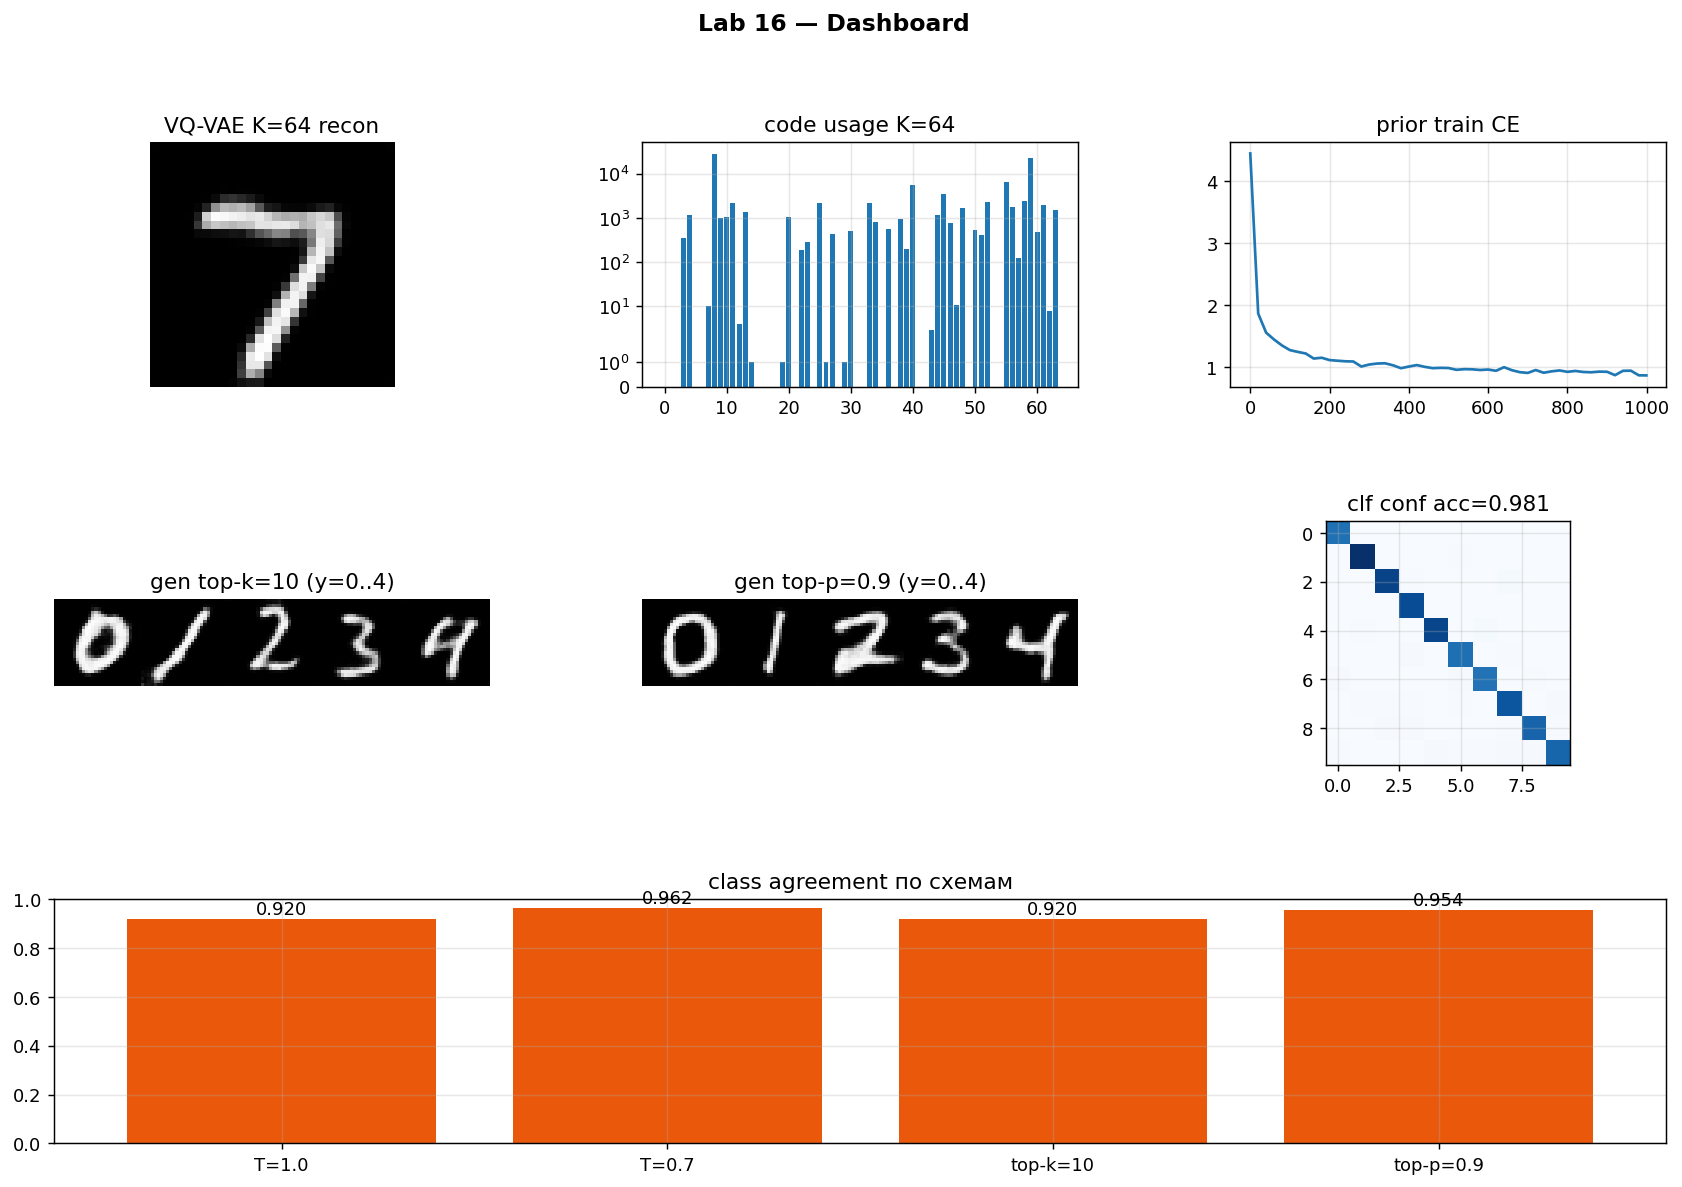

**`s1_arch_codemap.png`**

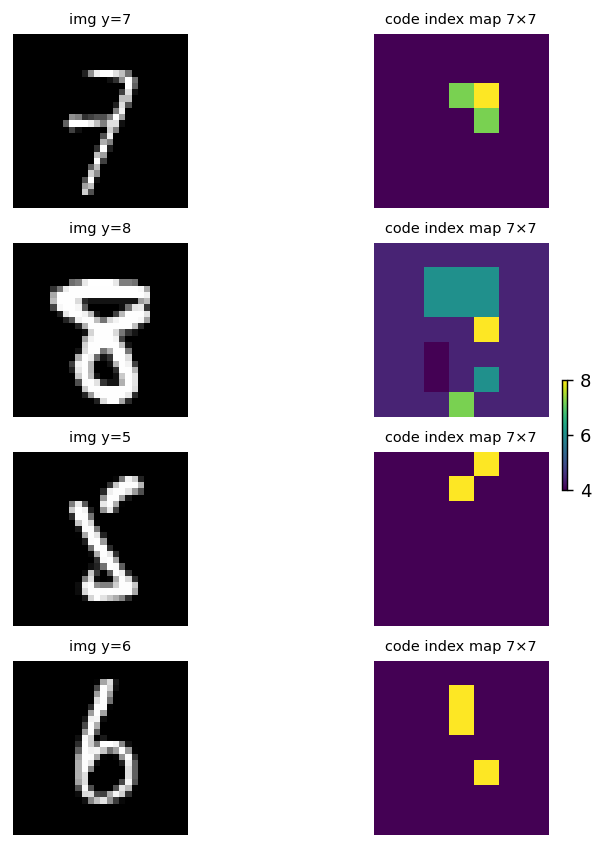

**`s1_arch_smoke.png`**

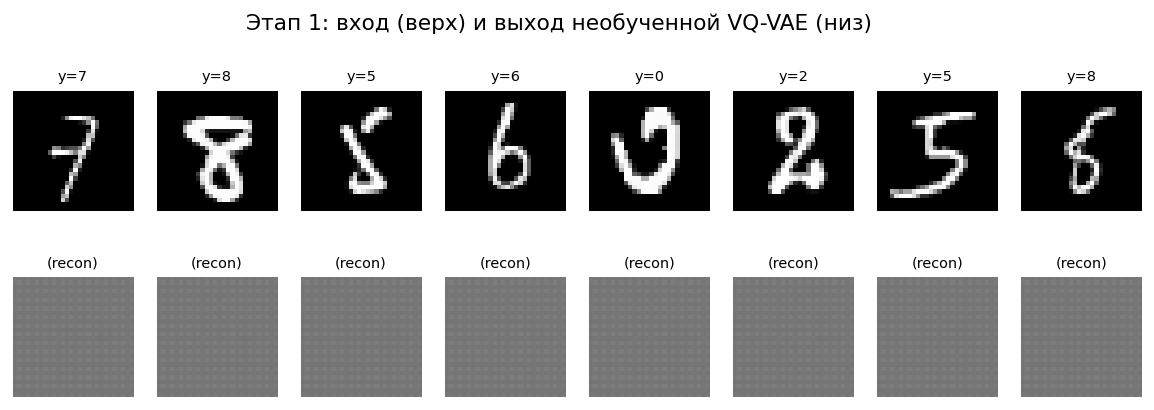

**`s1_smoke_codemap.png`**

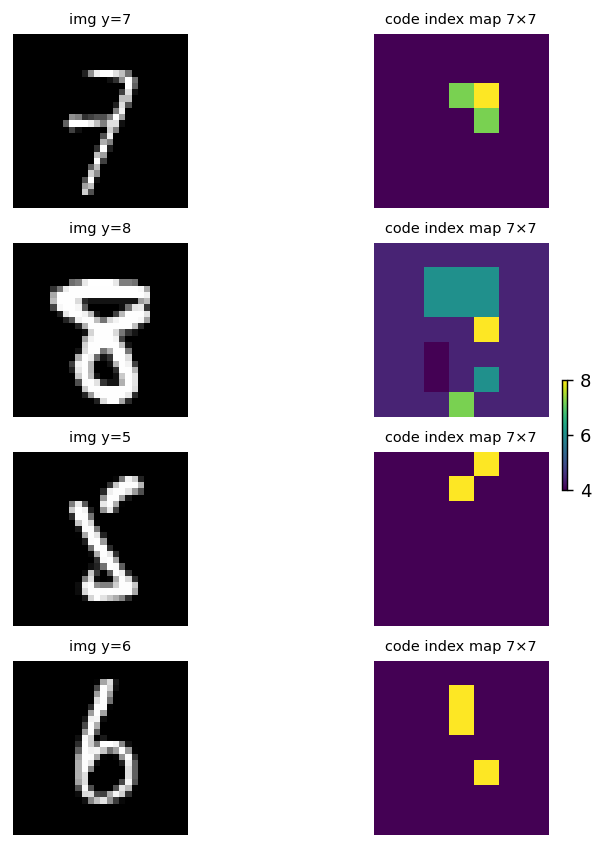

**`s1_smoke_recon.png`**

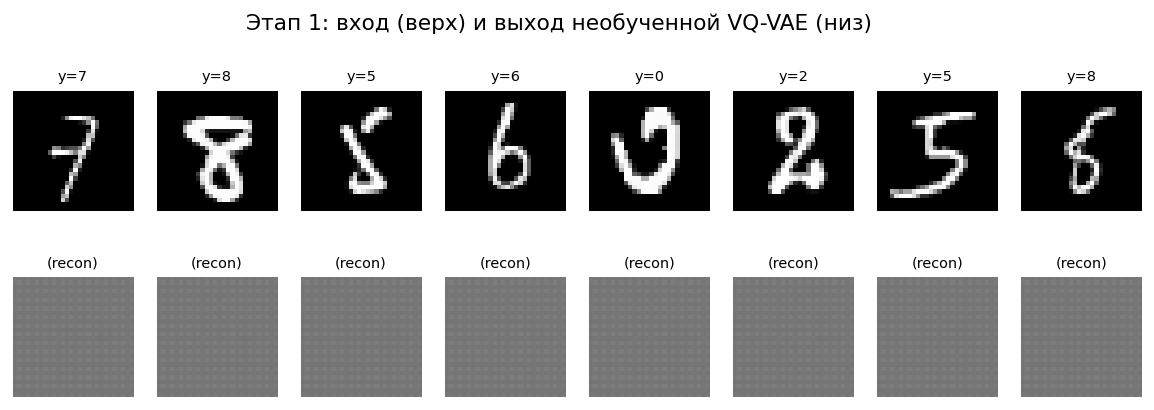

**`s2_code_usage.png`**

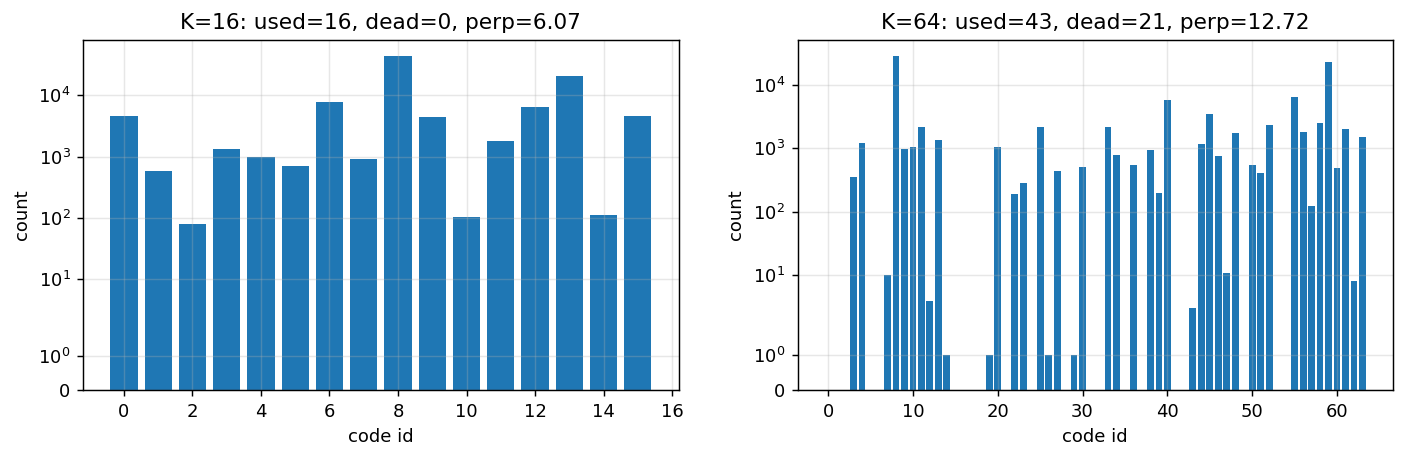

**`s2_curve_loss.png`**

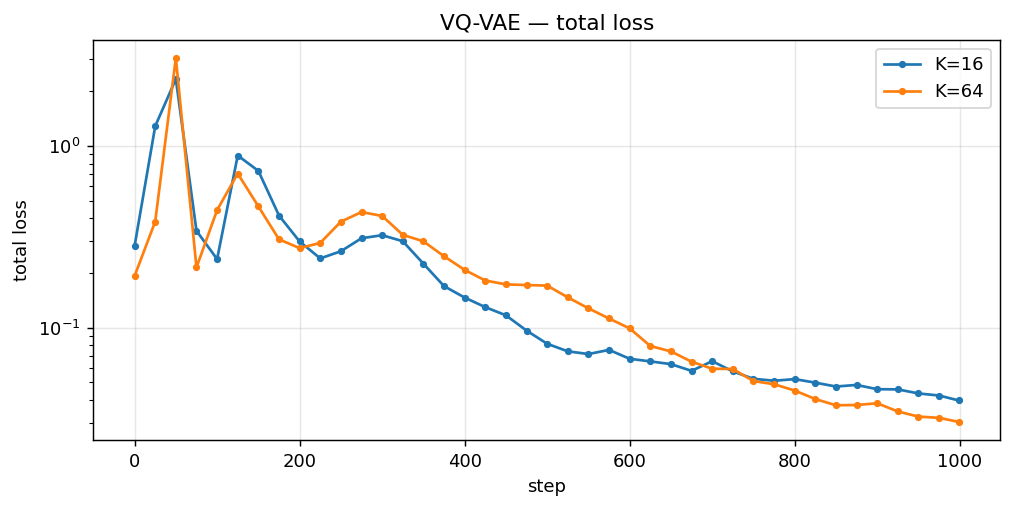

**`s2_curve_perp.png`**

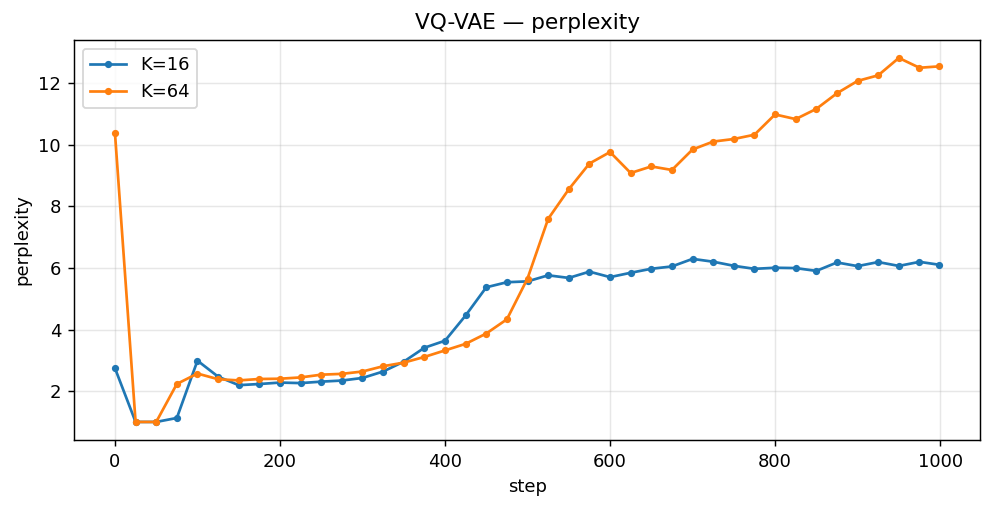

**`s2_curve_recon.png`**

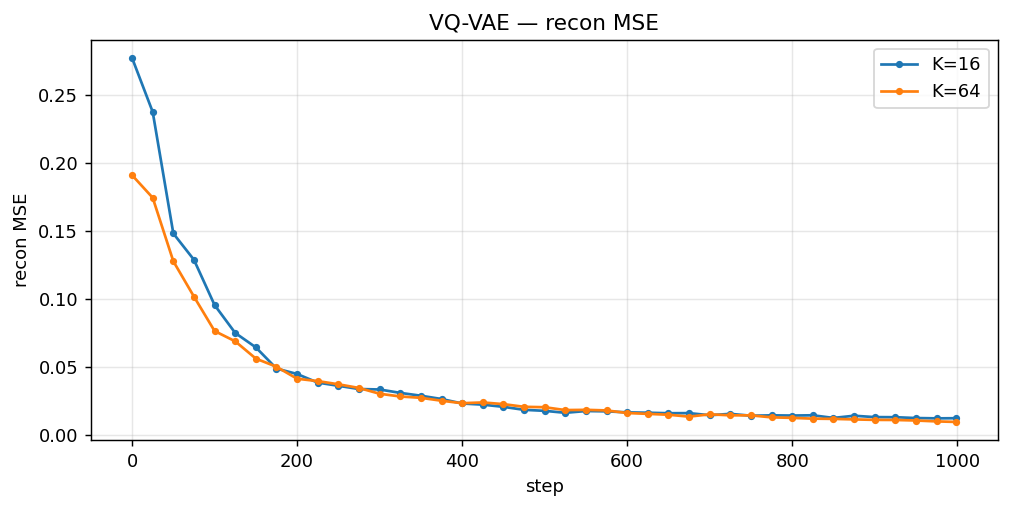

**`s2_curve_vq.png`**

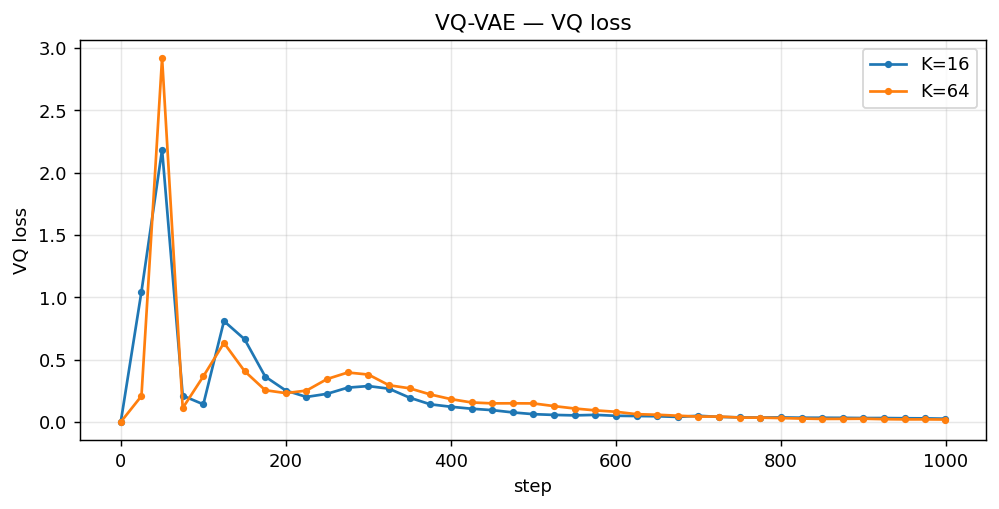

**`s2_recon_K16.png`**

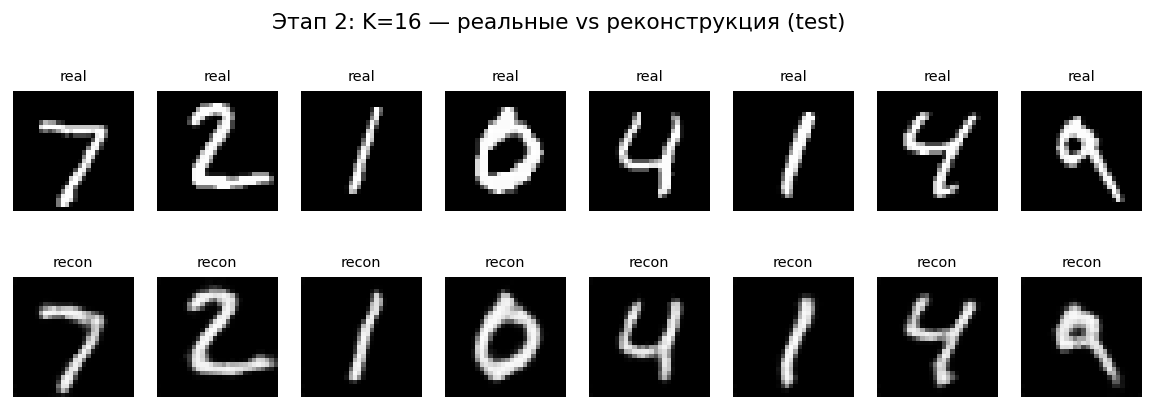

**`s2_recon_K64.png`**

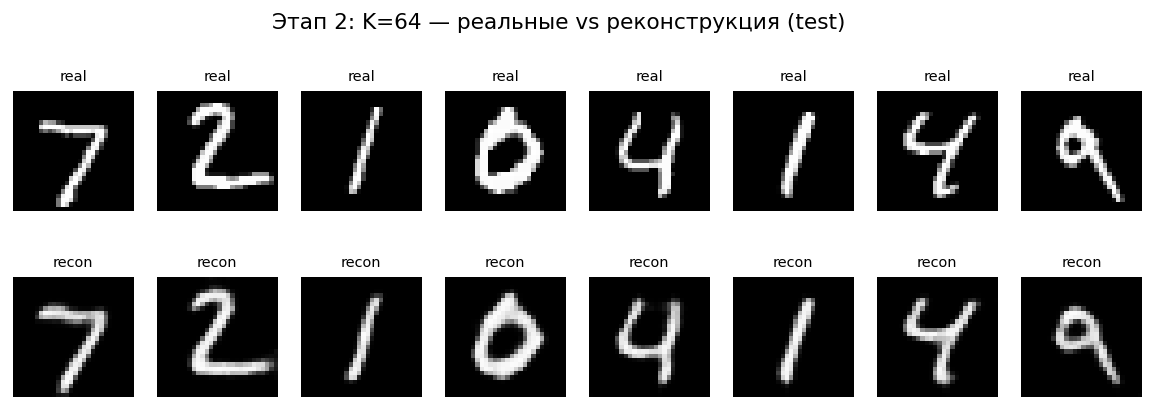

**`s3_examples.png`**

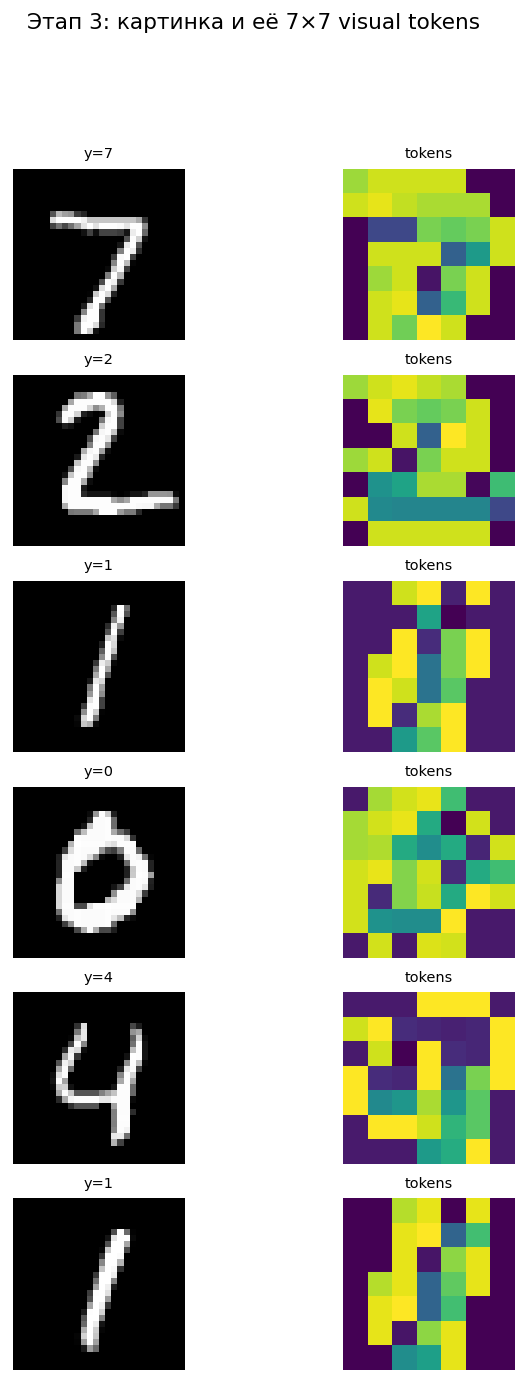

**`s3_token_distribution.png`**

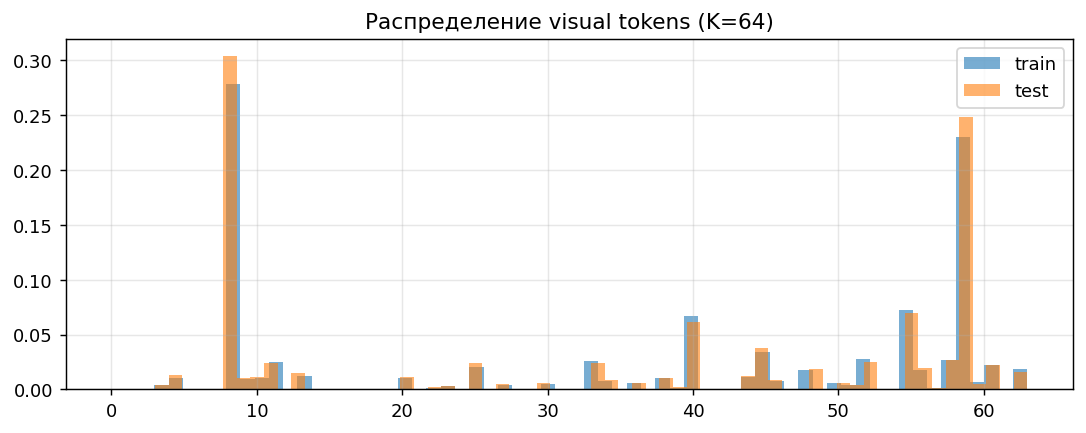

**`s4_causal_mask.png`**

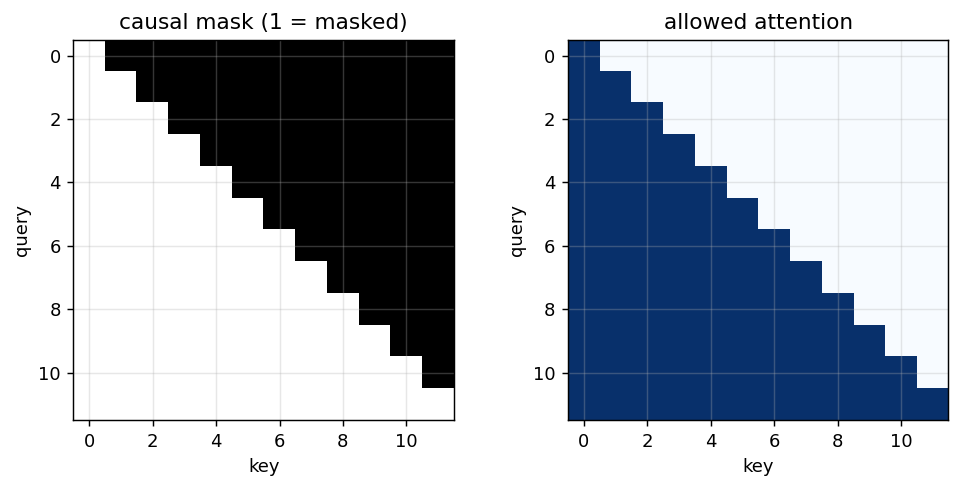

**`s4_causal_mask_diff.png`**

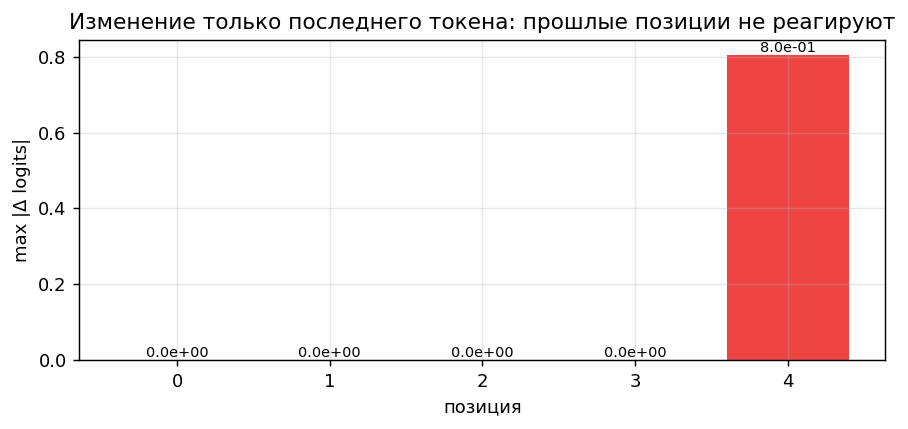

**`s5_prior_train.png`**

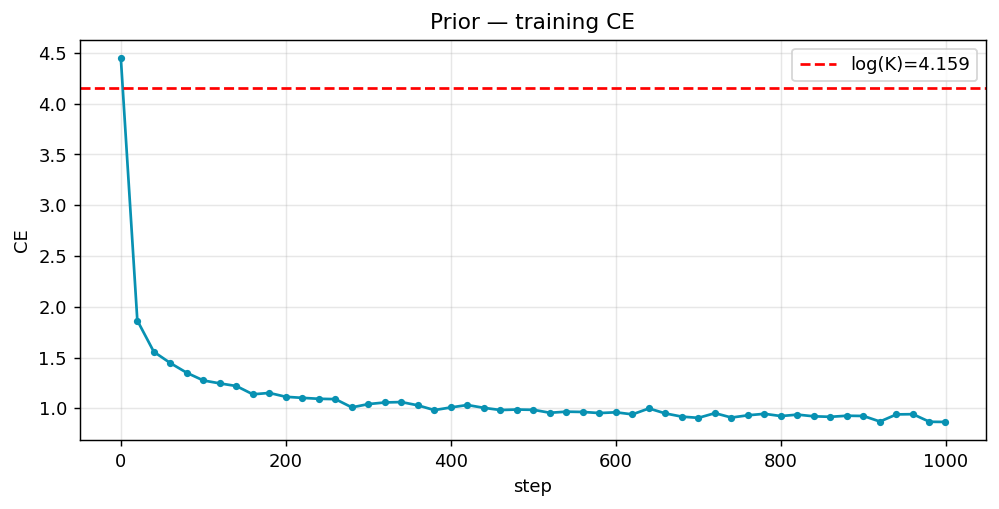

**`s6_prior_test_ce.png`**

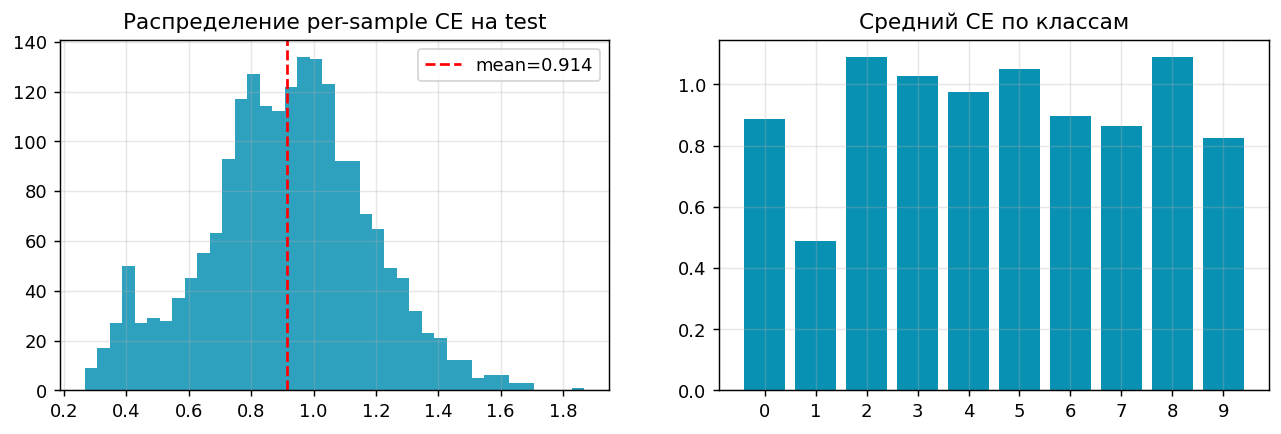

**`s8_clf_confusion.png`**

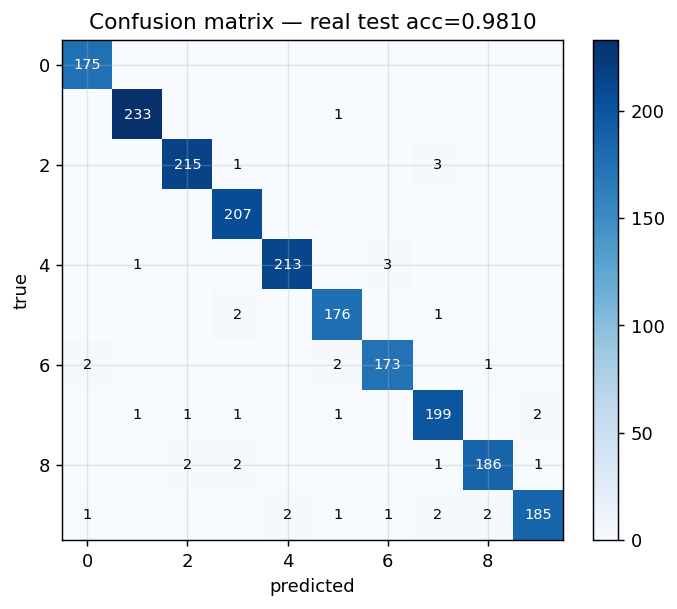

**`s8_clf_train.png`**

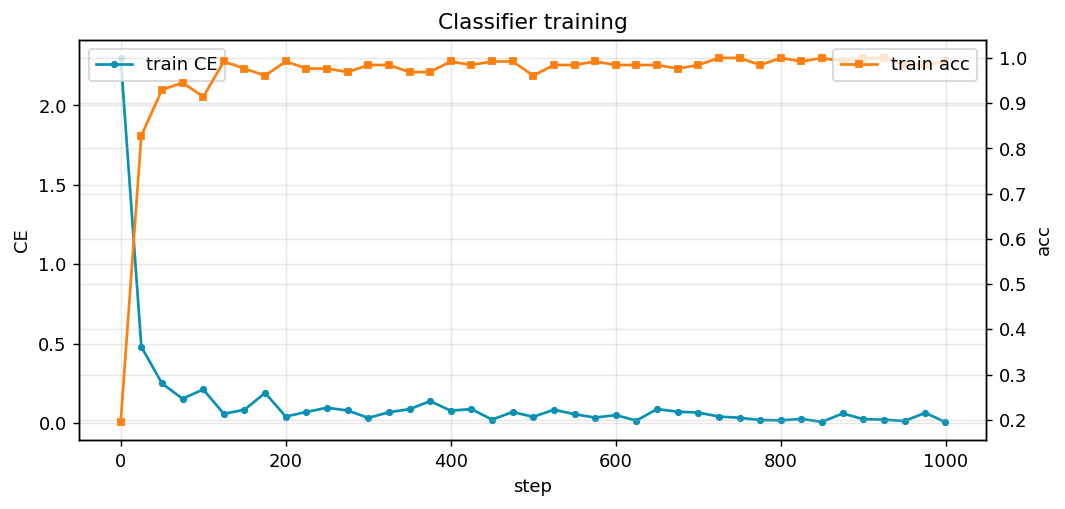

**`s9_sampled_tokens.png`**

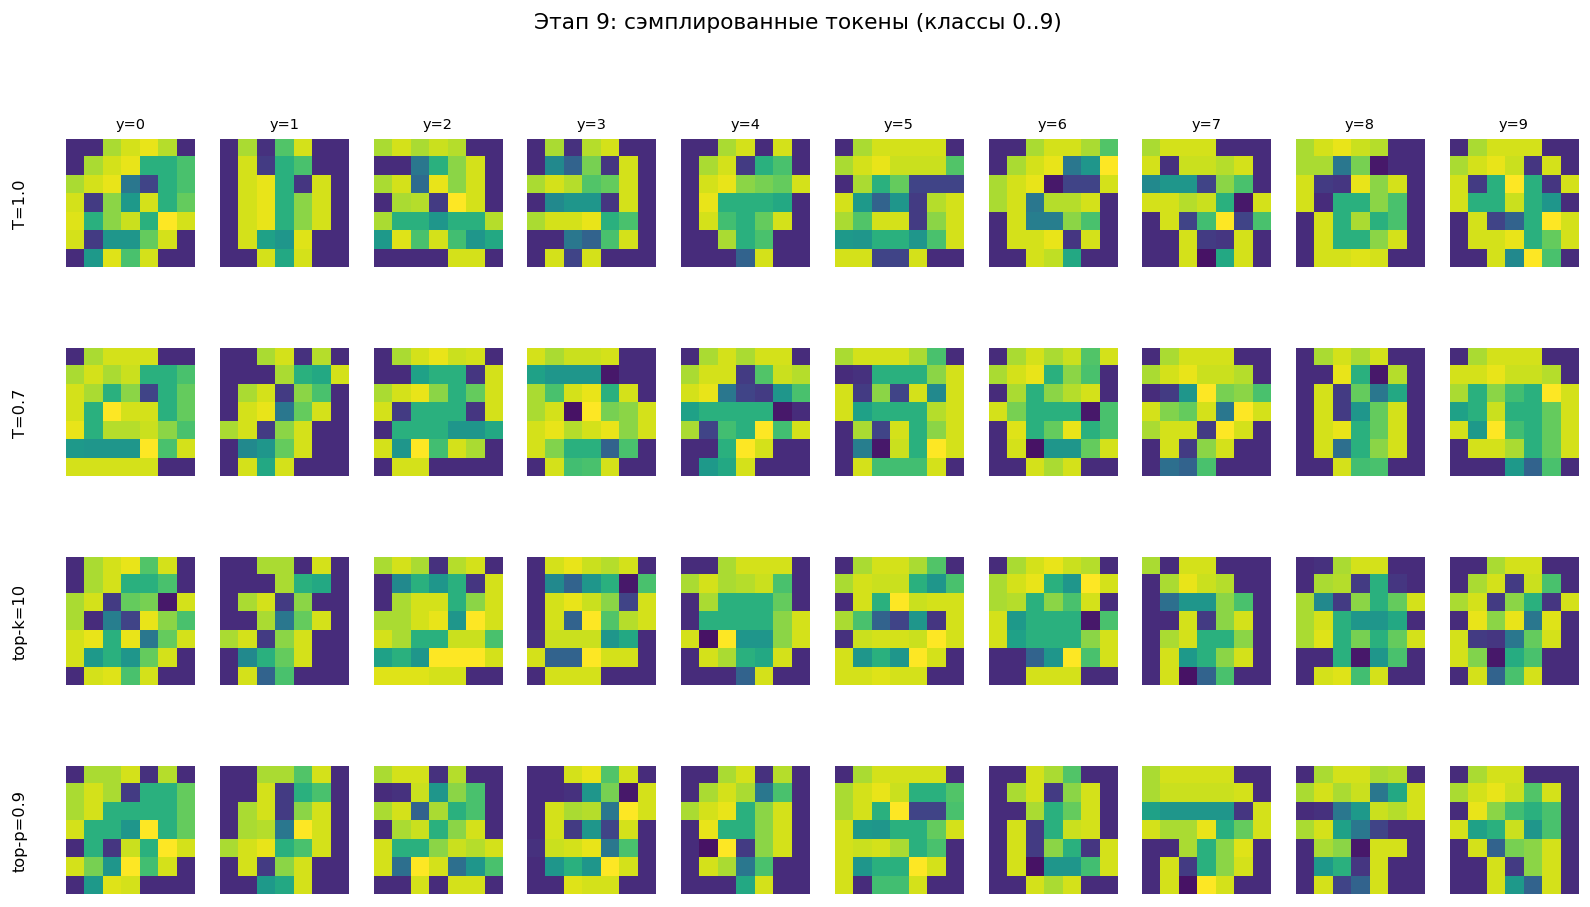

- `classifier.pt` — 1650.8 KB

- `final_report.json` — 1.3 KB

- `prior_K64.pt` — 4769.6 KB

- `prior_K64_L6.pt` — 4769.8 KB

- `s10_generation.json` — 0.5 KB

- `s11_ablation.json` — 0.4 KB

... (7 outputs left out)

- `tokens_K64.pt` — 8583.6 KB

- `vqvae_K16.pt` — 558.3 KB

- `vqvae_K64.pt` — 570.3 KB

- `vqvae_arch_check.json` — 0.2 KB

In [ ]:
stage_header(12, "Итоговый отчёт и дашборд", "Все метрики, графики и артефакты")

final = {
    "config": {"seed": SEED, "device": DEVICE, "fast_dev_run": FAST_DEV_RUN,
               "steps": STEPS, "batch": BATCH, "D": LATENT_DIM,
               "torch": torch.__version__,
               "torchvision": __import__("torchvision").__version__,
               "numpy": np.__version__},
    "vqvae": {k: {kk: vv for kk, vv in v.items()
                  if kk not in ("hist","counts","demo_in","demo_out")}
              for k, v in vqvae_metrics.items()},
    "prior":      {"test_ce": prior_test_ce, "ce_per_class": ce_cls.tolist()},
    "classifier": {"test_acc": clf_acc},
    "generation": {n: {"acc": r["acc"], "n": r["n"]} for n, r in gen_results.items()},
    "data": {"source": "torchvision MNIST", "license": "CC BY-SA 3.0",
             "train_used": 20000, "test_used": 2000},
}
save_json("final_report.json", final)

rows = [
    ("Device / fast_run",        f"{DEVICE} / {FAST_DEV_RUN}"),
    ("Steps",                    STEPS),
    ("VQ-VAE K=16 test MSE",     f"{vqvae_metrics['K16']['test_mse']:.5f}"),
    ("VQ-VAE K=64 test MSE",     f"{vqvae_metrics['K64']['test_mse']:.5f}"),
    ("K=64 used / dead",         f"{vqvae_metrics['K64']['used']} / {vqvae_metrics['K64']['dead']}"),
    ("K=64 perplexity",          f"{vqvae_metrics['K64']['perplexity']:.2f}"),
    ("Prior test CE",            f"{prior_test_ce:.4f}"),
    ("Classifier test acc",      f"{clf_acc:.4f}"),
] + [(f"Gen: {n}", f"{r['acc']:.4f}") for n, r in gen_results.items()]
metrics_table("FINAL SUMMARY", rows, accent="#0f172a")

# --- Дашборд ---
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(3, 3, hspace=0.55, wspace=0.35)

ax = fig.add_subplot(gs[0, 0])
ax.imshow(vqvae_metrics["K64"]["demo_out"][0, 0], cmap="gray"); ax.axis("off")
ax.set_title("VQ-VAE K=64 recon")

ax = fig.add_subplot(gs[0, 1])
cc = vqvae_metrics["K64"]["counts"].numpy()
ax.bar(np.arange(64), cc); ax.set_yscale("symlog")
ax.set_title("code usage K=64")

ax = fig.add_subplot(gs[0, 2])
ax.plot([h["step"] for h in prior_hist], [h["ce"] for h in prior_hist])
ax.set_title("prior train CE")

ax = fig.add_subplot(gs[1, 0])
ax.imshow(np.hstack([gen_results["top-k=10"]["demo"][i, 0].numpy() for i in range(5)]),
          cmap="gray", vmin=0, vmax=1); ax.axis("off")
ax.set_title("gen top-k=10 (y=0..4)")

ax = fig.add_subplot(gs[1, 1])
ax.imshow(np.hstack([gen_results["top-p=0.9"]["demo"][i, 0].numpy() for i in range(5)]),
          cmap="gray", vmin=0, vmax=1); ax.axis("off")
ax.set_title("gen top-p=0.9 (y=0..4)")

ax = fig.add_subplot(gs[1, 2])
ax.imshow(clf_conf.numpy(), cmap="Blues")
ax.set_title(f"clf conf acc={clf_acc:.3f}")

ax = fig.add_subplot(gs[2, :])
names = list(gen_results); vals = [gen_results[n]["acc"] for n in names]
bars = ax.bar(names, vals, color="#ea580c")
ax.set_ylim(0, 1); ax.set_title("class agreement по схемам")
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.3f}", ha="center")
fig.suptitle("Lab 16 — Dashboard", fontsize=13, fontweight="bold")
_savefig(fig, "s12_dashboard.png")

# --- Финальный дамп всех PNG из artifacts/figures ---
display(HTML('<div style="background:#0f172a;color:white;padding:10px 14px;'
             'border-radius:8px;font-family:sans-serif;margin:14px 0;'
             'font-weight:700">📊 ВСЕ сохранённые графики</div>'))
for p in sorted(FIG_DIR.glob("*.png")):
    display(Markdown(f"**`{p.name}`**"))
    display(Image(filename=str(p)))

# --- Артефакты ---
display(HTML('<div style="background:#0f172a;color:white;padding:10px 14px;'
             'border-radius:8px;font-family:sans-serif;margin:14px 0;'
             'font-weight:700">💾 Checkpoints / JSON</div>'))
for f in sorted(ARTIFACTS.glob("*.*")):
    if f.suffix in (".pt", ".json"):
        display(Markdown(f"- `{f.name}` — {f.stat().st_size/1024:.1f} KB"))

success("Все этапы выполнены. Артефакты в artifacts/")

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.

# Выводы лабораторной работы №16



Мы научили нейросеть рисовать цифры MNIST «по кусочкам», как языковая модель пишет текст. Сначала специальный сжиматель (VQ-VAE) превращает каждую картинку 28×28 в сетку 7×7 маленьких чисел — «визуальных токенов». Потом отдельная модель-предсказатель (prior) учится угадывать следующее число по предыдущим, зная, какую цифру нужно нарисовать. В конце мы «раскодировали» токены обратно в картинки и проверили отдельным классификатором, совпадают ли нарисованные цифры с заказанными.

## Главные числа

| Что измеряли | Результат | Как читать |
|---|---|---|
| Ошибка восстановления, K=16 | **0.0122** | сжиматель K=16 теряет больше деталей |
| Ошибка восстановления, K=64 | **0.0101** | K=64 на 18% точнее — словарь больше, картинка чётче |
| Сколько кодов реально используется (K=64) | **43 из 64** | 21 код «мёртвый» — ёмкость словаря недогружена |
| Perplexity кодов | **12.7** | эффективно работает ~13 кодов, распределение токенов неравномерное |
| Ошибка предсказания токенов (CE) | **0.914** | очень хороший результат: в 4.5 раза лучше «случайного угадывания» |
| Точность классификатора на настоящих MNIST | **98.1%** | «судья» надёжен, он не занижает оценку генерации |
| Качество генерации при T=0.7 | **96.2%** | 962 из 1000 сгенерированных цифр опознаны как заказанный класс |
| Качество генерации при top-p=0.9 | **95.4%** | почти так же хорошо, но с чуть большим разнообразием |
| Качество генерации при T=1.0 и top-k=10 | **92.0%** | базовый уровень, есть куда улучшать |

## Что это значит

1. **Больший словарь помогает, но не полностью.** K=64 восстанавливает картинки точнее, чем K=16, но использует только 43 из 64 кодов. Это значит: словарь можно было бы ещё «разгрузить», если обучать дольше или агрессивнее подталкивать мёртвые коды к работе. Сейчас часть ёмкости простаивает.

2. **Модель-предсказатель работает очень хорошо.** Ошибка CE = 0.914 при 64 возможных токенах говорит о том, что модель редко «удивляется» правильному следующему токену. Это подтверждается и высокой точностью генерации — 92–96%.

3. **Классификатор-судья не виноват в низких оценках.** Его собственная точность 98.1% на настоящих MNIST — значит, когда мы говорим «сгенерированная цифра не совпала с классом», это реальная ошибка генератора, а не ошибка проверяющего.

4. **Настройки семплирования важны.** Простое понижение температуры до 0.7 даёт **+4.2 процентных пункта** к качеству генерации. Модель становится «увереннее» в выборе токенов. Top-p=0.9 почти так же хорош (+3.4 п.п.) и оставляет больше разнообразия. А вот top-k=10 в этой задаче бесполезен — при словаре из 64 токенов он отсекает либо слишком много, либо слишком мало, и результат не отличается от базового.

5. **Более глубокий prior чуть точнее, но разница в качестве картинок не видна.** Мы проверили гипотезу: 6-слойный Transformer предсказывает токены точнее, чем 4-слойный (CE 0.900 против 0.914). Но когда мы декодировали его токены в картинки, качество оказалось тем же — 91.6% против 92.0%, а такая разница статистически неотличима от нуля. Объяснение: на 1000 шагов обучения и на такой простой задаче (10 классов, 49 токенов) 6 слоёв не успевают раскрыть преимущество. Это видно на CE, но ещё не видно на картинках.

## Где модель ошибается

Наиболее частые путаницы — между похожими цифрами:
- **4 ↔ 9** — у них общая «петля» в верхней части;
- **3 ↔ 8** — обе двугорбые;
- **7 ↔ 1** — тонкие вертикальные штрихи дают похожие токены;
- **5 ↔ 6** — верхняя часть отличается одним-двумя токенами;
- **8 с разрывом** — токены правильные, но декодер сглаживает разрыв в петле.

Это структурные ограничения маленького словаря: 64 токена не всегда хватает, чтобы различить тонкие топологические отличия.





Сжиматель K=64 превращает MNIST в последовательности из 49 токенов почти без потерь, autoregressive prior с температурой 0.7 генерирует цифры, которые независимый классификатор узнаёт в **96.2%** случаев, а более глубокая модель точнее предсказывает токены, но на текущем бюджете это ещё не видно на итоговых картинках.